# Mogamat Tayyib Dawood - ST10132915
# PDAN8412 – Portfolio of Evidence: Image Recognition with Convolutional Neural Networks


Business problem:<br> The publisher wants to use facial recognition at all its premises. As a first step, this notebook trains a CNN image-recognition model on a large, openly available labelled image set. Faces are not required at this stage, so I use underwater fish images. They pose the same core problem as CCTV face recognition: identifying an individual class from small, low-quality camera crops taken in uncontrolled conditions.

Dataset:<br> Fish Recognition Ground-Truth data (Fish4Knowledge project), Kaggle link for dataset:
<https://www.kaggle.com/datasets/madhushreesannigrahi/fish-recognition-ground-truth-data/data> [1]

Original source:<br> <https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/> [2], [3].



## AI assistance and code attribution

Declaration of AI Usage
Mogamat Tayyib Dawood
ST10132915
PDAN8412 – POE Part 3

I hereby declare that I have used AI tools to guide me and understand certain aspects of the assignment.

Tools Utilised: 

Claude (anthropic): used to explain concepts and to help with certain parts of the code (listed in the Code attribution section of the notebooks, links also below).

Grammarly: used for grammar and spelling correction.

Nature and Extent of AI Usage: 

I used Claude to guide my understanding of three topics: (1) how a CNN learns from images and how to choose a baseline architecture and its hyperparameters, (2) avoiding data leakage when many frames come from the same fish, and evaluating a heavily imbalanced multi-class problem, and (3) how to apply statistical feature selection when the CNN learns its own features from pixels. For four parts of the code I also used Claude for help, which is listed in the Code attribution section of the notebook.

https://claude.ai/share/6a5a929c-0a1b-4611-8bbc-c255734c6a9b

https://claude.ai/share/77955de8-f039-4b02-aa79-3fc1f8f18cc8

https://claude.ai/share/5d451c2a-41a2-4ec7-af1c-6cc846c8a238

Proofreading:

 Grammarly was used for spelling and phrasing improvements in the text interpretations.

Statement of Originality:

  I can explain every step in this notebook. Code that was guided by an AI tool is listed in the Code attribution section of the notebook. All other code, data interpretation and conclusions are my own original work.



## Code attribution
| Notebook section | Source (tool, tutorial or URL) | Extent | What I changed |
|---|---|---|---|
| Section 3.1: image_info Spark UDF (loading and measuring images) | CLaude, https://claude.ai/share/2ab02860-196b-495a-ae4d-1cbe684e40d8 | Pattern for returning several values from a UDF with a StructType schema, and the Laplacian blur measure | I chose the descriptors, wrote the file-name parsing for my folder structure, added the -1 marker for unreadable files, and used the UDF after Spark's image reader failed on my Windows laptop. |
| Section 5: one-way ANOVA from Spark aggregations and UnivariateFeatureSelector | Claude, https://claude.ai/share/0836f3cc-ef38-4226-be2b-70c3483c715e | Formula for combining per-species counts, means and variances into an F-value, and the selector settings | I chose the ten descriptors and the p < 0.05 threshold, left fish area out of the model inputs, and wrote the decisions table. |
| Section 6: two-stage StratifiedGroupKFold split and leakage check | Claude, https://claude.ai/share/f942725a-4b1a-4d4b-8ddf-14bb6afd846f | Approach for a nested grouped split | I grouped on traj_key, set the 60/20/20 ratios, and added the random-split comparison that measures the leakage. |
| Sections 9 and 10: Model 2 conv_block, callbacks, square-root class weights and McNemar's test | Claude, https://claude.ai/share/d6ac2814-49eb-4c96-91e3-1e86efc329b2 | Structure of conv_block and the callbacks; exact binomial form of McNemar's test | I chose the dropout schedule, the square-root weighting, the patience values and the epoch limit, and compared Model 2 with Model 1. |


## 1. Dataset choice and justification

### 1.1 Why this data suits a CNN
A CNN learns from grid-structured data where nearby values are related, which is what an image is. Its convolution filters slide across the image and learn local patterns (edges, stripes, fin shapes, colour patches). Pooling layers then combine these into larger shapes. Every image is labelled with its species, so this is a supervised multi-class image classification problem, which is exactly the task a CNN is built for.

| Requirement for CNN image recognition | How this dataset meets it |
|---|---|
| Large volume (brief: ≥ 10 000 records) | 27 370 verified fish images (plus 27 370 matching masks) |
| Reliable labels | Labels were checked by marine biologists in a clustering-assisted annotation process [3] |
| Visual differences between classes | 23 species that differ in colour, stripes, body shape and fins |
| Real-world conditions | Frames from 10 live underwater cameras in Taiwan: varying light, blur, water colour and distance, which mirrors CCTV footage |
| Open licence | Free to use, modify and distribute for any purpose if the source is acknowledged [2] |

Link to the publisher's goal:<br> Recognising a fish species from a small, cropped camera detection is technically the same problem as recognising a person from a CCTV face crop. Both involve low resolution, changing lighting and pose, several frames of the same individual, and some classes that appear far more often than others. The pipeline built here (Spark EDA, grouped splitting, a CNN, imbalance-aware evaluation) carries over directly to a face dataset later.

### 1.2 Data quality and common pitfalls
| Pitfall | Why it matters | How I handle it |
|---|---|---|
| Severe class imbalance: the largest species has about 12 000 images while several have under 50 | A model can reach high accuracy by always predicting the common species | Measure it in EDA; use macro-F1 and balanced accuracy; retrain with class weights |
| Near-duplicate frames: images come from video trajectories, so one fish appears in many almost identical frames | A random split puts frames of the same fish in both train and test, which inflates the scores (data leakage) [4] | Split by trajectory ID so a fish is in only one of train, validation or test |
| Variable, small image sizes: crops range from about 20 px to 250 px | A CNN needs a fixed input size, and stretching distorts the fish's shape | Pad-and-resize to a fixed square size chosen from the size distribution |
| Underwater quality: blur, low contrast, colour cast | Can hide the features that separate species | Measure brightness, contrast and sharpness per class; use augmentation |
| Exact duplicates and corrupt files | Duplicates bias training and evaluation; corrupt files crash training | Hash every image in Spark and drop exact duplicates and unreadable files |
| Species with very few trajectories | Cannot be split into train, validation and test without leakage | Keep species with at least 15 trajectories (decision taken in Section 4) |

## 2. Analysis plan

| Stage | Planned steps | Tools | Output that feeds the next stage |
|---|---|---|---|
| a. EDA and cleaning | Load every image and mask into a Spark DataFrame, with a Spark UDF decoding the images in parallel. Parse species and trajectory from the file paths. Use Spark aggregations for: class counts and imbalance ratio; frames per trajectory; width, height and aspect ratio; brightness, contrast and sharpness (variance of the Laplacian, a standard blur measure); mean colour per class; fish area from the masks; SHA-256 hashes for duplicates; unreadable files. Then visualise the results and look at sample images | PySpark, Spark SQL, Matplotlib and Seaborn | Cleaning rules, input size, split strategy, imbalance strategy |
| b. Feature selection | Pixels are learned by the CNN, so "features" here means which inputs and classes to keep. (1) ANOVA F-test with p-value selection in Spark (UnivariateFeatureSelector, keep p < 0.05) on image descriptors (colour, size, brightness, sharpness, fish area). This replaces forward or backward elimination, which suits tabular data but not pixels. (2) Decisions: RGB or grayscale, input resolution, padding or stretching, which species to keep | Spark ML, pandas | Final input specification and class list |
| c. Train model | Grouped, stratified split by trajectory (60 / 20 / 20) using StratifiedGroupKFold. Model 1 baseline: 3 Conv–Pool blocks → Dense(128) → Dropout(0.5) → Softmax; Adam (lr = 0.001), batch size 64, 10 epochs, sparse categorical cross-entropy. Model 2 retrain (if needed): augmentation, batch normalisation, global average pooling, class weights, early stopping and learning-rate reduction | TensorFlow / Keras, tf.data | Trained models and training history |
| d. Interpret and evaluate | On the untouched test set: accuracy, macro-F1 (main metric, since every species counts equally), balanced accuracy, weighted F1, top-3 accuracy, Cohen's kappa, per-class precision, recall and F1, a row-normalised confusion matrix, learning curves (to check for over- or under-fitting), and baselines (majority class; logistic regression on hand-made features). McNemar's test checks whether Model 2 is significantly better than Model 1 | scikit-learn, SciPy | Evidence that the model works, and its weak points |
| e. Report | Short PDF for the client: data and quality → cleaning → EDA visuals → how the model was trained → results and what they mean → recommendations for the facial-recognition rollout (including POPIA) |  PDF | Final submission |

Further considerations from my own research
- Trajectory-grouped splitting avoids the leakage that random splits cause on video-derived data, so the scores reflect fish the model has never seen.
- Past Fish4Knowledge studies note the strong imbalance [5], so accuracy on its own would be misleading.
- In a real facial-recognition deployment, face images are biometric special personal information under POPIA [6]. Consent, purpose limitation and secure storage must be planned before the publisher collects face data.

In [1]:
# All my importss are here.
import os, sys, json, time, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Hiding library warnings and TensorFlow's start-up messages so the outputs stay readable.
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"


# Settings I use throughout the notebook.
# One fixed seed so the split and results are the same every time I run this.
SEED = 42

# The images are in data/fish-recognition-ground-truth-data next to this notebook.
DATA_DIR = os.environ.get("FISH_DATA_DIR", "data/fish-recognition-ground-truth-data")
OUT_DIR = "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")

# Model input size. I chose 64 x 64 from the image size distribution in Section 3.4.
IMG_SIZE = 64
BATCH = 64

# 10 epochs for the baseline and at most 15 for the retrained model, so training finishes on my laptop CPU.
EPOCHS_BASE = int(os.environ.get("FISH_EPOCHS_BASE", 10))
EPOCHS_IMPROVED = int(os.environ.get("FISH_EPOCHS_IMPROVED", 15))

# A speciess needs at least 15 trajectories (individual fish) so every split can get different fish.
MIN_TRAJ = int(os.environ.get("FISH_MIN_TRAJ", 15))

# Images smaller than 16 pixels on a side are too small to be useful.
MIN_SIDE = 16

random.seed(SEED); np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

# Sppecies names from the Fish4Knowledge ground-truth page. The folder number is the key.
SPECIES = {1: "Dascyllus reticulatus", 2: "Plectroglyphidodon dickii", 3: "Chromis chrysura", 4: "Amphiprion clarkii", 5: "Chaetodon lunulatus", 6: "Chaetodon trifascialis", 7: "Myripristis kuntee", 8: "Acanthurus nigrofuscus", 9: "Hemigymnus fasciatus",
           10: "Neoniphon sammara", 11: "Abudefduf vaigiensis", 12: "Canthigaster valentini",
           13: "Pomacentrus moluccensis", 14: "Zebrasoma scopas", 15: "Hemigymnus melapterus", 16: "Lutjanus fulvus", 17: "Scolopsis bilineata", 18: "Scaridae",
           19: "Pempheris vanicolensis", 20: "Zanclus cornutus", 21: "Neoglyphidodon nigroris", 22: "Balistapus undulatus", 23: "Siganus fuscescens"}

# Short label for plots, for example 1 becomes '01 D. reticulatus'.
def short_name(cid):
    parts = SPECIES.get(cid, str(cid)).split()
    nm = parts[0] if len(parts) == 1 else f"{parts[0][0]}. {parts[1]}"
    return f"{cid:02d} {nm}"

# Saving every figure to a folder so I can use the same images in the report.
def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()



print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.5.3 | pandas 2.3.3


In [2]:
# Spark has to use the same Python as my notebook, otherwise the workers can't run my UDF

os.environ["PYSPARK_PYTHON"] = sys.executable

os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F, types as T


# LLoccal Spark session that uses all my CPU cores. Spark does the analysis; TensorFlow trains the CNN, as the brief allows.

# The progress bars are switched off because they fill the output.
spark = (SparkSession.builder
         .appName("PDAN8412-POE-Fish-CNN")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Spark version: 4.2.0


## 3. Exploratory Data Analysis with Spark

### 3.1 Loading every image into a Spark DataFrame
Python lists the image files, and Spark spreads the work across its worker processes [7]. A Spark UDF opens each image and returns its height, width and number of channels, plus quality descriptors:

- mean R, G, B: average colour
- brightness: mean grey level
- contrast: standard deviation of grey levels
- sharpness: variance of the Laplacian (low values mean a blurry image)
- fg_fraction: share of bright pixels (used on the masks to measure how much of the crop is fish)

A SHA-256 hash of the pixel bytes identifies exact duplicates. Species ID, trajectory (tracking) ID and fish ID are parsed from the folder and file names 
(fish_< tracking id>_< fish id>.png).

Spark's built-in image reader was not used because it depends on Hadoop native libraries that are usually missing on Windows (it failed on my laptop). The UDF produces the same information on any operating system.


In [3]:
# 3.1 Loading every image into Spark.

# Spark's built-in image reader failed on my Windows laptop because it needs Hadoop libraries, so Python lists the files and a Spark UDF opens and measures each image in parallel instead.
paths = sorted(os.path.join(root, f) for root, _, files in os.walk(DATA_DIR)
               for f in files if f.lower().endswith((".png", ".jpg", ".jpeg")))
print(f"Found {len(paths):,} image files")

# One row per file. 

paths_df = (spark.createDataFrame([(p.replace("\\", "/"),) for p in paths], ["uri"])
                 .repartition(max(8, (os.cpu_count() or 2) * 4)))

# The columns my UDF returns for each image.

stat_fields = ["mean_r", "mean_g", "mean_b", "brightness", "contrast", "sharpness", "fg_fraction"]

info_schema = T.StructType([T.StructField("height", T.IntegerType()), T.StructField("width", T.IntegerType()), T.StructField("channels", T.IntegerType()), T.StructField("hash", T.StringType())]
                           + [T.StructField(n, T.DoubleType()) for n in stat_fields])


# Openss one image and measures its size, colour, brightness, contrast and blur.
@F.udf(info_schema)
def image_info(path):
    import hashlib
    try:
        with Image.open(path) as im:
            im.load()
            channels = len(im.getbands())
            arr = np.asarray(im.convert("RGB") if channels >= 3 else im.convert("L"), dtype=np.uint8)
    except Exception:
        # A file that can't be opened gets -1 so I can count corrupt files later.
        return (-1, -1, -1, None) + (None,) * len(stat_fields)
    h, w = arr.shape[:2]



    # Identical pixels give an identical hash, which is how I find exact duplicates.

    digest = hashlib.sha256(arr.tobytes() + str(arr.shape).encode()).hexdigest()
    a = arr.astype(np.float32)
    r, g, b = (a, a, a) if a.ndim == 2 else (a[..., 0], a[..., 1], a[..., 2])

    # Grey level is a weighted mix of red, green and blue (the standard formula).
    gray = 0.299 * r + 0.587 * g + 0.114 * b

    # Laplacian: compares each pixel with its four neighbours. Low variance means a blurry image.
    lap = (4 * gray[1:-1, 1:-1] - gray[:-2, 1:-1] - gray[2:, 1:-1] - gray[1:-1, :-2] - gray[1:-1, 2:]
           if h >= 3 and w >= 3 else np.zeros(1))



    # The last value is the share of bright pixels. On a mask that is the share of the crop covered by the fish.
    return (int(h), int(w), int(channels), digest, float(r.mean()), float(g.mean()), float(b.mean()),
            float(gray.mean()), float(gray.std()), float(lap.var()), float((gray > 127).mean()))


# Species, trajectory and fish ID all come from the folder and file names (fish_<tracking id>_<fish id>.png).

# traj_key commbines species and tracking ID, so one value means one individual fish.
imgs = (paths_df.withColumn("s", image_info("uri")).select("uri", "s.*")
          .withColumn("fname", F.regexp_extract("uri", r"([^/]+)\.[A-Za-z]+$", 1))
          .withColumn("folder", F.regexp_extract("uri", r"/([^/]+)/[^/]+$", 1))
          .withColumn("kind", F.when(F.lower("folder").contains("mask") | F.lower("fname").startswith("mask"),
                                     "mask").otherwise("fish"))
          .withColumn("class_id", F.regexp_extract("folder", r"(\d{2})", 1).cast("int"))
          .withColumn("tracking_id", F.regexp_extract("fname", r"(\d+)_(\d+)$", 1))
          .withColumn("fish_id", F.regexp_extract("fname", r"(\d+)_(\d+)$", 2))
          .withColumn("key", F.concat_ws("_", "tracking_id", "fish_id"))
          .withColumn("traj_key", F.concat_ws("_", F.col("class_id").cast("string"), "tracking_id"))
          .withColumn("aspect", F.when(F.col("height") > 0, F.col("width") / F.col("height")))
          .cache())

# count() makes Spark actually read every image. cache() keeps the results so later cells are fast.
t0 = time.time()

n_files = imgs.count()


print(f"Spark loaded {n_files:,} image files in {time.time() - t0:.0f}s")

Found 54,740 image files
Spark loaded 54,740 image files in 98s


In [4]:
# Checking that the species and IDs were read correctly before I analyse anything.
imgs.select("folder", "fname", "kind", "class_id", "tracking_id", "fish_id", "height", "width", "channels").show(5, truncate=40)
imgs.groupBy("kind").count().show()


# Every file must have a species number in its folder name, otherwise it can't be labelled.

n_unparsed = imgs.filter(F.col("class_id").isNull()).count()
assert n_unparsed == 0, ("Some files have no species number in their folder name. Check the folder names "
                         "and adjust the class_id regular expression.")

# Fish images and masks are analysed separately.
fish = imgs.filter(F.col("kind") == "fish")


masks = imgs.filter(F.col("kind") == "mask")

# Registering the fish images as a table so I can also query them with Spark SQL.

fish.createOrReplaceTempView("fish")
print("Schema used for analysis:")
fish.printSchema()

+-------+-----------------------+----+--------+------------+-------+------+-----+--------+
| folder|                  fname|kind|class_id| tracking_id|fish_id|height|width|channels|
+-------+-----------------------+----+--------+------------+-------+------+-----+--------+
|fish_01|fish_000026450001_02607|fish|       1|000026450001|  02607|    72|   72|       3|
|fish_01|fish_000017990001_01724|fish|       1|000017990001|  01724|    70|   79|       3|
|fish_01|fish_000006970001_00724|fish|       1|000006970001|  00724|   198|  204|       3|
|fish_01|fish_000004890001_00629|fish|       1|000004890001|  00629|   208|  192|       3|
|fish_01|fish_000127079598_07263|fish|       1|000127079598|  07263|    76|   87|       3|
+-------+-----------------------+----+--------+------------+-------+------+-----+--------+
only showing top 5 rows
+----+-----+
|kind|count|
+----+-----+
|fish|27370|
|mask|27370|
+----+-----+

Schema used for analysis:
root
 |-- uri: string (nullable = true)
 |-- height:

### 3.2 Class distribution: how many images and trajectories per species?

,class_id,images,trajectories,imgs_per_traj,species,share_%
0,1,12112,4240,2.9,Dascyllus reticulatus,44.25
1,2,2683,1225,2.2,Plectroglyphidodon dickii,9.80
2,3,3593,1175,3.1,Chromis chrysura,13.13
3,4,4049,1021,4.0,Amphiprion clarkii,14.79
4,5,2534,536,4.7,Chaetodon lunulatus,9.26
5,6,190,79,2.4,Chaetodon trifascialis,0.69
6,7,450,71,6.3,Myripristis kuntee,1.64
7,8,218,71,3.1,Acanthurus nigrofuscus,0.80
8,9,241,58,4.2,Hemigymnus fasciatus,0.88
9,10,299,53,5.6,Neoniphon sammara,1.09


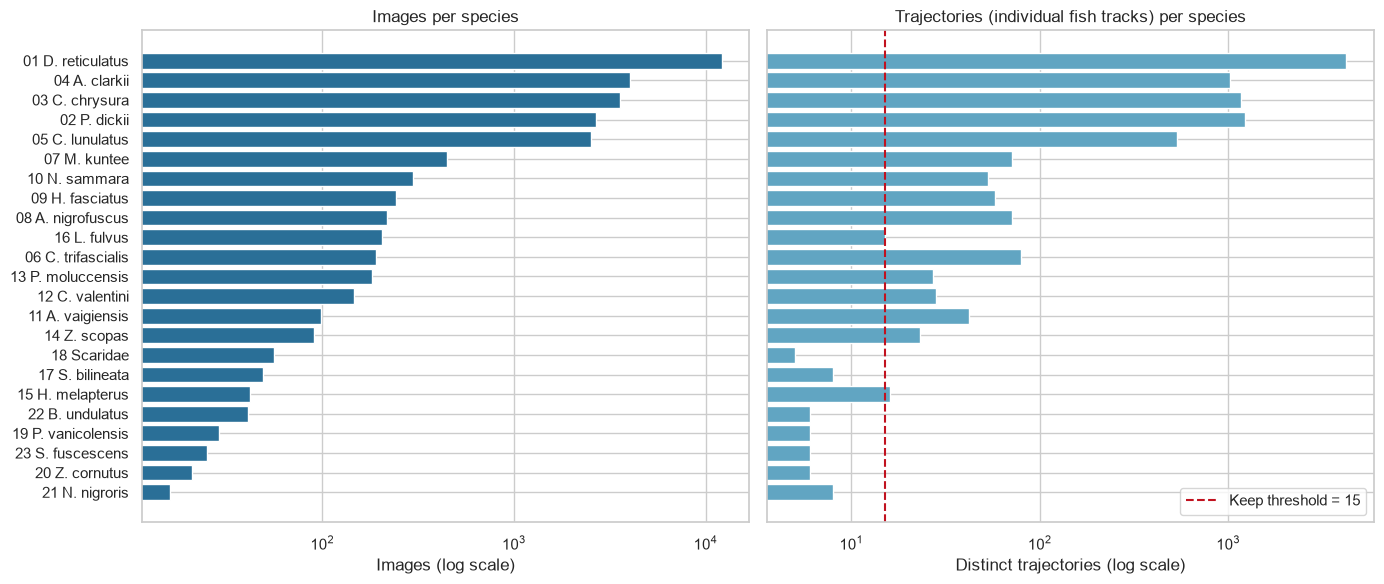

Key findings: 23 species, 27,370 fish images.
- Largest class: Dascyllus reticulatus with 12,112 images (44.25% of the data).
- Imbalance ratio (largest / smallest class): 757 : 1.
- Species with fewer than 100 images: 10; species with fewer than 15 trajectories: 7.
- A model that always predicts 'Dascyllus reticulatus' would already score 44.25% accuracy.


In [5]:
# 3.2 Images and individual fish (trajectories) per species, using Spark SQL.
# height > 0 leaves ourt any unreadable files.
class_stats = spark.sql('''
    SELECT class_id,
           COUNT(*)                    AS images,
           COUNT(DISTINCT traj_key)    AS trajectories,
           ROUND(COUNT(*) / COUNT(DISTINCT traj_key), 1) AS imgs_per_traj
    FROM fish
    WHERE height > 0
    GROUP BY class_id
    ORDER BY class_id
''')
cs = class_stats.toPandas()
cs["species"] = cs.class_id.map(SPECIES)
cs["share_%"] = (100 * cs.images / cs.images.sum()).round(2)
display(cs)


# I use a log scale becausee the largest species has hundreds of times more images than the smallest.

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
order = cs.sort_values("images", ascending=True)
labels = [short_name(c) for c in order.class_id]
axes[0].barh(labels, order.images, color="#2a6f97")

axes[0].set_xscale("log"); axes[0].set_xlabel("Images (log scale)"); axes[0].set_title("Images per species")
axes[1].barh(labels, order.trajectories, color="#61a5c2")

axes[1].set_xscale("log"); axes[1].set_xlabel("Distinct trajectories (log scale)"); axes[1].set_title("Trajectories (individual fish tracks) per species")

# The red line shows my 15-trajectory threshold for keeping a species.
axes[1].axvline(MIN_TRAJ, color="#c1121f", ls="--", label=f"Keep threshold = {MIN_TRAJ}")
axes[1].legend(loc="lower right")
savefig("01_class_distribution")

# Printing the key numbers so I can quote them in the report.
top = cs.loc[cs.images.idxmax()]
print(f"Key findings: {len(cs)} species, {cs.images.sum():,} fish images.")
print(f"- Largest class: {top.species} with {top.images:,} images ({top['share_%']}% of the data).")
print(f"- Imbalance ratio (largest / smallest class): {cs.images.max() / cs.images.min():.0f} : 1.")
print(f"- Species with fewer than 100 images: {(cs.images < 100).sum()}; "
      f"species with fewer than {MIN_TRAJ} trajectories: {(cs.trajectories < MIN_TRAJ).sum()}.")

# Always guessing the buiggest species already gives this accuracy, so accuracy alone can't be my main metric.
print(f"- A model that always predicts '{top.species}' would already score {top['share_%']}% accuracy.")

Interpretation:<br> The data is heavily long-tailed: one species (Dascyllus reticulatus) supplies a large share of all images, and the five most common species supply roughly nine in ten images. This has three consequences for training:
1. Accuracy alone is misleading, because always predicting the majority class already scores highly. Macro-F1 and balanced accuracy become the main metrics.
2. The rare species need class weighting or augmentation, or the CNN will learn to ignore them.
3. The right panel matters more than the left. A species with many images but few trajectories is really just a few fish filmed many times, so its effective sample size is much smaller.

### 3.3 Trajectories: near-duplicate frames and leakage risk

 mean_frames  median  max_frames
        3.14       2          92


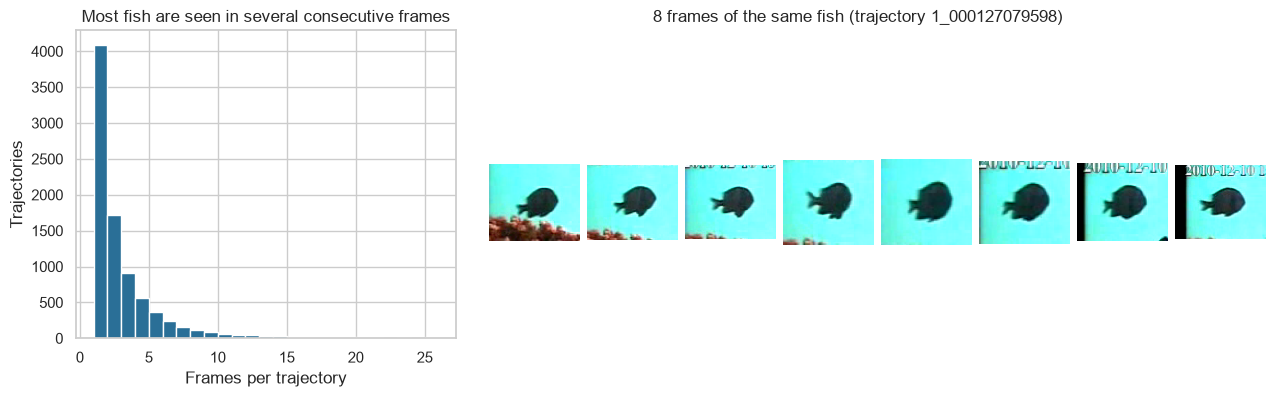

In [6]:
# 3.3 How many frames does each individual fish appear in?
traj = (fish.filter("height > 0").groupBy("class_id", "traj_key").count()
            .withColumnRenamed("count", "frames"))
traj_pd = traj.toPandas()
print(traj.select(F.mean("frames").alias("mean_frames"), F.expr("percentile_approx(frames, 0.5)").alias("median"), F.max("frames").alias("max_frames")).toPandas().round(2).to_string(index=False))

# The histogram stops at the 99th percentile so a few very long tracks don't squash the plot.
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.6]})

axes[0].hist(traj_pd.frames, bins=range(1, int(traj_pd.frames.quantile(0.99)) + 2), color="#2a6f97")
axes[0].set_xlabel("Frames per trajectory"); axes[0].set_ylabel("Trajectories")
axes[0].set_title("Most fish are seen in several consecutive frames")

# Showing 8 frames of one long trajectory, to make the near-duplicates (and the leakage risk) visible.
# fish_id is text, so I cast it to a number first, otherwise frame 10 would come before frame 2.

long_traj = traj_pd.sort_values("frames", ascending=False).iloc[min(5, len(traj_pd) - 1)].traj_key
frames = (fish.filter(F.col("traj_key") == long_traj).orderBy(F.col("fish_id").cast("int")).select("uri").limit(8).toPandas())
axes[1].axis("off"); axes[1].set_title(f"8 frames of the same fish (trajectory {long_traj})")

# Each frame gets its own small set of axes next to the histogram.

for i, p in enumerate(frames["uri"]):
    ax = fig.add_axes([0.42 + i * 0.07, 0.15, 0.065, 0.6]); ax.imshow(Image.open(p).convert("RGB")); ax.axis("off")
plt.savefig(os.path.join(FIG_DIR, "02_trajectories.png"), dpi=150, bbox_inches="tight"); plt.show()

Interpretation:<br> Frames from one trajectory are almost ideentical. If the data were split randomly, the test set would contain fish that the model had already seen in training, and the scores would be inflated.<br> Decision: split by traj_key (Section 6) and quantify how much leakage a random split would have caused.

### 3.4 Image size and shape

,min_w,median_w,p95_w,max_w,min_h,median_h,p95_h,max_h,mean_aspect
0,25,95,175,428,27,88,157,401,1.08


Colour channels:
  channels  count
        3  27370


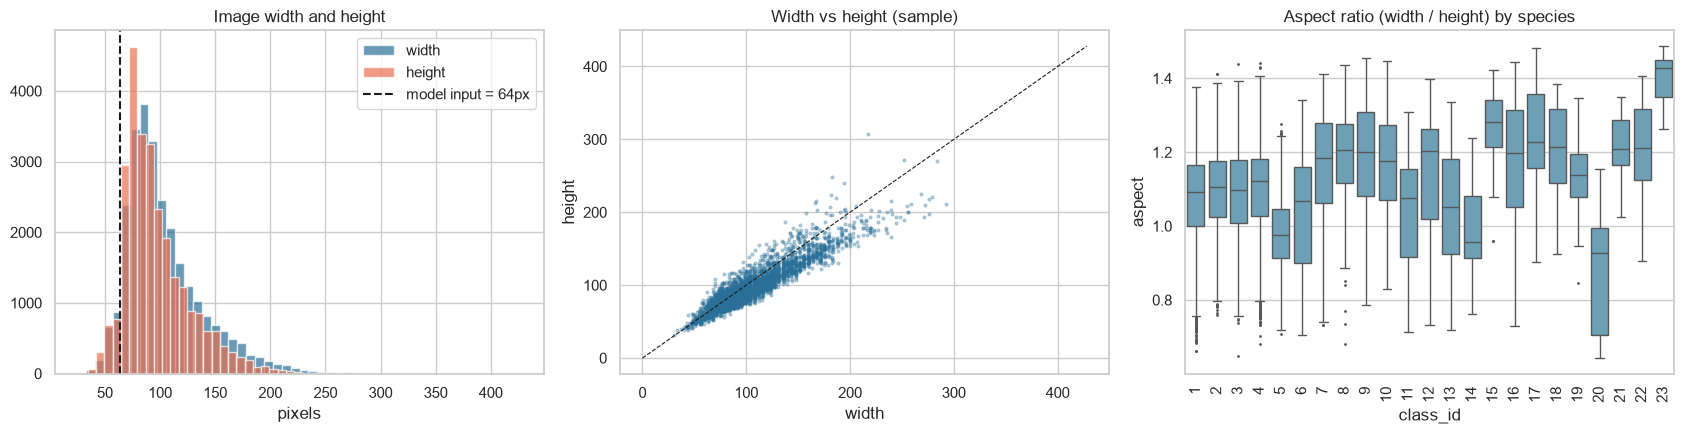

In [7]:
# 3.4 Image size and shape, summarised in Spark.

# The median and 95th percentile tell me which input size keeps most of the detail.


size_stats = (fish.filter("height > 0")
              .agg(F.min("width").alias("min_w"), F.expr("percentile_approx(width, 0.5)").alias("median_w"),
                   F.expr("percentile_approx(width, 0.95)").alias("p95_w"), F.max("width").alias("max_w"),
                   F.min("height").alias("min_h"), F.expr("percentile_approx(height, 0.5)").alias("median_h"),
                   F.expr("percentile_approx(height, 0.95)").alias("p95_h"), F.max("height").alias("max_h"),
                   F.round(F.avg("aspect"), 2).alias("mean_aspect"))
              .toPandas())

display(size_stats)

# All images should be colour (3 channels).

channels = fish.groupBy("channels").count().toPandas(); print("Colour channels:\n", channels.to_string(index=False))


dims = fish.filter("height > 0").select("class_id", "width", "height", "aspect").toPandas()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# a) Width and height, with my 64-pixel input size marked.
axes[0].hist(dims.width, bins=50, alpha=.7, label="width", color="#2a6f97")
axes[0].hist(dims.height, bins=50, alpha=.7, label="height", color="#e76f51")
axes[0].axvline(IMG_SIZE, color="k", ls="--", label=f"model input = {IMG_SIZE}px"); axes[0].legend()
axes[0].set_xlabel("pixels"); axes[0].set_title("Image width and height")

# b) Width against height for a sample of 4 000 images. Points on the dashed line are square.


smp = dims.sample(min(4000, len(dims)), random_state=SEED)

axes[1].scatter(smp.width, smp.height, s=4, alpha=.3, color="#2a6f97")
axes[1].plot([0, dims.width.max()], [0, dims.width.max()], "k--", lw=.8)
axes[1].set_xlabel("width"); axes[1].set_ylabel("height"); axes[1].set_title("Width vs height (sample)")

# c) Aspect ratio per species. If it differs by species, shape is useful, so I should pad instead of stretching.
order_ids = sorted(dims.class_id.unique())

sns.boxplot(data=dims, x="class_id", y="aspect", order=order_ids, ax=axes[2], color="#61a5c2", fliersize=1)
axes[2].set_title("Aspect ratio (width / height) by species"); axes[2].tick_params(axis="x", rotation=90)
savefig("03_image_sizes")

Interpretation:<br> The crops are small and of different sizes, and the aspect ratio clearly depends on the species: deep-bodied fish are close to square, while elongated species are wide. Two decisions follow:
- Input size: Most images are under about 100 px, so a 64 × 64 input keeps most of the detail without scaling up tiny images too much, and it keeps CPU training fast.
- Pad, don't stretch: resize_with_pad keeps the body shape (which differs by species) instead of squashing every fish into a square.

### 3.5 Image quality: brightness, contrast and blur

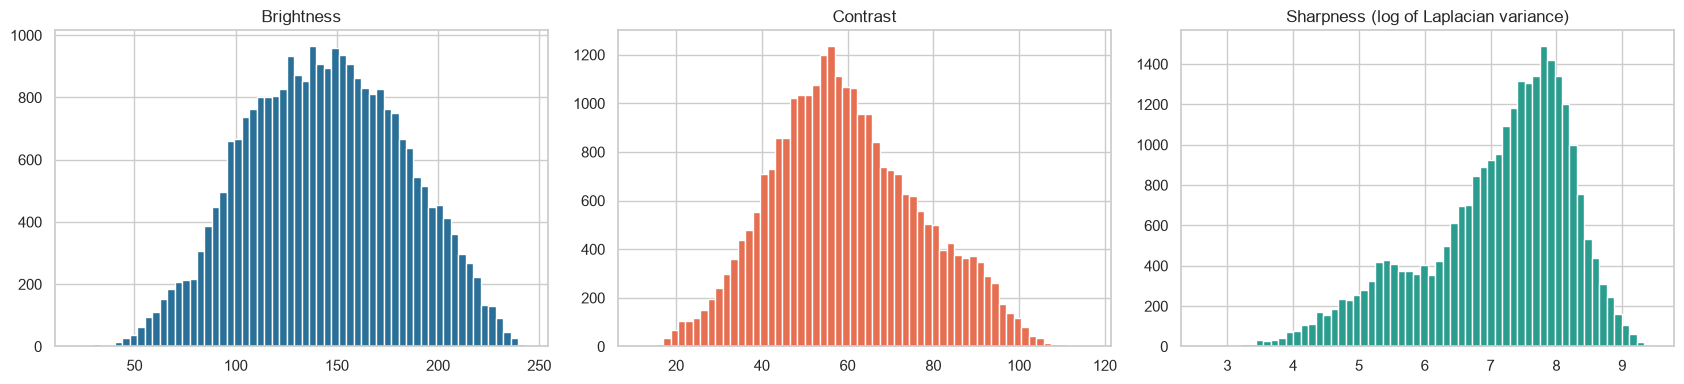

,class_id,avg_brightness,avg_contrast,median_sharpness
0,1,164.2,67.3,1650.6
1,2,134.2,44.4,516.6
2,3,132.5,55.1,773.6
3,4,129.3,55.7,1963.8
4,5,98.3,59.1,3889.5
5,6,151.3,71.0,2767.7
6,7,165.6,26.9,116.5
7,8,145.1,51.0,427.6
8,9,153.1,52.7,1034.0
9,10,105.9,51.9,1509.2


Blurriest 5% of images have Laplacian variance below 126.2. Dark images (brightness < 40): 16.


In [8]:
# 3.5 Image quality: brightness, contrast and blur.
quality = fish.filter("height > 0").select("class_id", "brightness", "contrast", "sharpness").toPandas()

# The blurriest 5% of images, used in the printout below.

q_low_sharp = quality.sharpness.quantile(0.05)

# Sharpness is very skewed, so I plot it on a log scale. The real values don't change.
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col, colr in zip(axes, ["brightness", "contrast", "sharpness"], ["#2a6f97", "#e76f51", "#2a9d8f"]):
    data = np.log1p(quality[col]) if col == "sharpness" else quality[col]
    ax.hist(data, bins=60, color=colr)
    ax.set_title(f"{col.capitalize()}" + (" (log of Laplacian variance)" if col == "sharpness" else ""))
savefig("04_quality_distributions")

# Averages per species in Spark, so I can see if some species are darker or blurrier than others.
qs = (fish.filter("height > 0").groupBy("class_id")
          .agg(F.round(F.avg("brightness"), 1).alias("avg_brightness"), F.round(F.avg("contrast"), 1).alias("avg_contrast"), F.round(F.expr("percentile_approx(sharpness, 0.5)"), 1).alias("median_sharpness"))
          .orderBy("class_id").toPandas())

display(qs)
print(f"Blurriest 5% of images have Laplacian variance below {q_low_sharp:.1f}. "
      f"Dark images (brightness < 40): {(quality.brightness < 40).sum():,}.")

Interpretation:<br> Brightness and contrast vary widely because of depth, time of day and water clarity, and a small tail of images is very blurred. These are genuine field conditions, not errors, so the images are kept (removing them would make the model fragile in real use). Instead, the retrained model uses contrast and zoom augmentation so it learns to handle this variation.

### 3.6 Colour by species

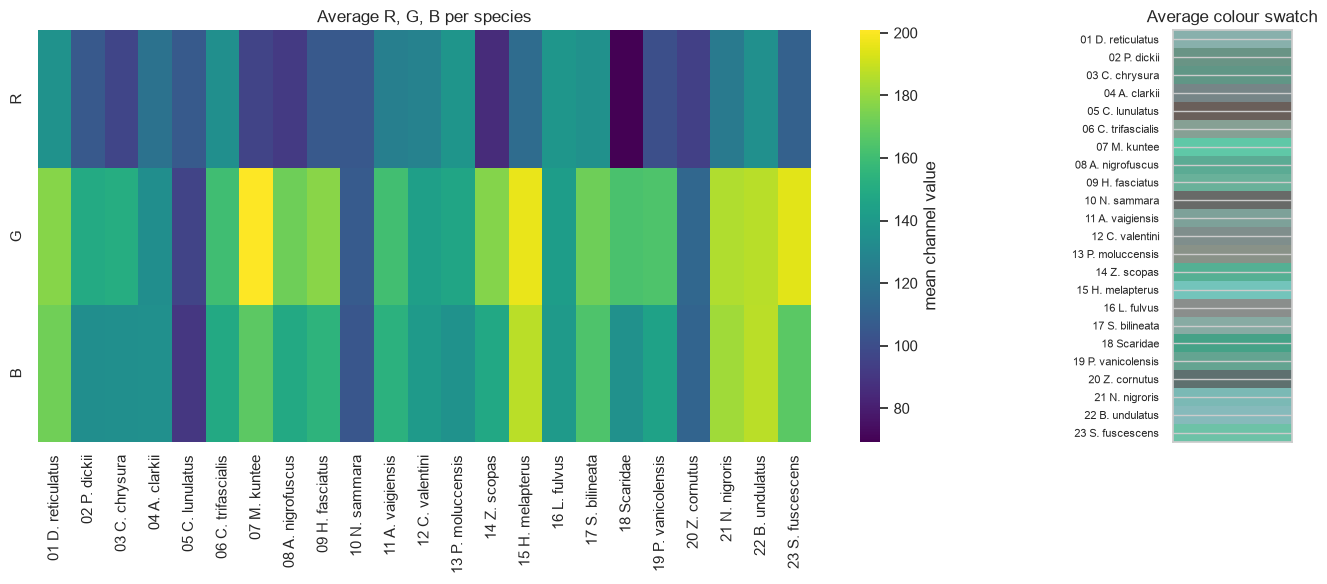

In [9]:
# 3.6 Average colour per species, in Spark.
colour = (fish.filter("height > 0").groupBy("class_id").agg(F.avg("mean_r").alias("R"), F.avg("mean_g").alias("G"), F.avg("mean_b").alias("B"))
              .orderBy("class_id").toPandas().set_index("class_id"))

colour.index = [short_name(c) for c in colour.index]


fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2, 1]})

# Heatmap of the red, green and blue averages.
sns.heatmap(colour.T, annot=False, cmap="viridis", ax=axes[0], cbar_kws={"label": "mean channel value"})
axes[0].set_title("Average R, G, B per species")

# The same averages shown as actual colours. Dividing by 255 puts them in the 0-1 range imshow expects.
axes[1].imshow((colour.values / 255).reshape(-1, 1, 3), aspect=0.15)
axes[1].set_yticks(range(len(colour))); axes[1].set_yticklabels(colour.index, fontsize=8); axes[1].set_xticks([])
axes[1].set_title("Average colour swatch")
savefig("05_colour_by_species")

Interpretation:<br> The average colour differs between species. Section  tests this statistically, and if confirmed, it is the evidence for keeping RGB input ratherd than converting to grayscale. The blue-green cast of the water is visible in every class, which is why per-channel scaling, rather than hand-made colour correction, is left for the network to learn.

### 3.7 Masks: how much of each crop is fish?

Fish images without a matching mask: 0


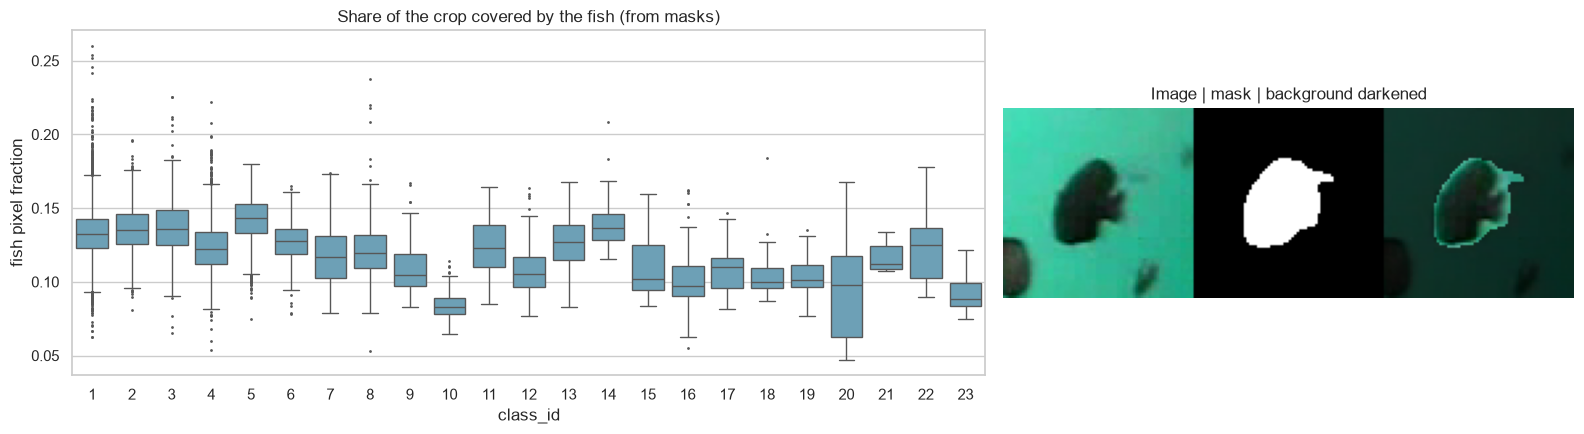

In [10]:
# 3.7 How much of each crop is fish? The masks answer this.

# I join each fish image to its mask on species and file key.
mask_area = masks.filter("height > 0").select("class_id", "key", F.col("fg_fraction").alias("fish_area"))
paired = fish.filter("height > 0").join(mask_area, ["class_id", "key"], "left")

# A fish image without a mask would show up as missing after the left join.
n_unpaired = paired.filter(F.col("fish_area").isNull()).count()

print(f"Fish images without a matching mask: {n_unpaired:,}")

area_pd = paired.select("class_id", "fish_area").dropna().toPandas()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})

sns.boxplot(data=area_pd, x="class_id", y="fish_area", ax=axes[0], color="#61a5c2", fliersize=1)
axes[0].set_title("Share of the crop covered by the fish (from masks)"); axes[0].set_ylabel("fish pixel fraction")

# One example: the image, its mask, and the image with the background darkened to 25%.
ex = paired.filter(F.col("fish_area").isNotNull()).select("uri", "class_id", "key").limit(1).toPandas().iloc[0]

mask_uri = masks.filter((F.col("class_id") == int(ex.class_id)) & (F.col("key") == ex.key)).select("uri").first()[0]
im = np.array(Image.open(ex.uri).convert("RGB"))
mk = np.array(Image.open(mask_uri).convert("L"))
overlay = im.copy(); overlay[mk < 128] = (overlay[mk < 128] * 0.25).astype(np.uint8)
axes[1].imshow(np.hstack([im, np.stack([mk] * 3, -1), overlay])); axes[1].axis("off")
axes[1].set_title("Image | mask | background darkened")
savefig("06_masks")

Interpretation:<br> The fish fills only part of each crop, and the rest is water and reef background. Because the model will see the full crop, it has to learn to focus on the fish. Global average pooling and augmentation in Model 2 help with this. The masks are used for EDA only, not as model input: at deployment the camera would supply only the crop, so training on masked images would create a mismatch between training and real use.

### 3.8 Duplicates and corrupt files

In [11]:
# 3.8 Corrupt files, exact duplicates and tiny images.
# Unreadable files were given a height of -1 by my UDF.


n_invalid = fish.filter(F.col("height") <= 0).count()

# Images with the same hash have identical pixels. I also count how many species each group belongs to.

dup_groups = (fish.filter("height > 0").groupBy("hash").agg(F.count("*").alias("copies"), F.countDistinct("class_id").alias("n_classes")).filter("copies > 1"))
n_dup_groups = dup_groups.count()

# Extra copies are the duplicates beyond the first one in each group.
n_dup_extra = dup_groups.agg(F.sum(F.col("copies") - 1)).first()[0] or 0

# Identical images labelled as different species would be contradictory labels.

n_conflict = dup_groups.filter("n_classes > 1").count()

n_small = fish.filter((F.col("height") > 0) & ((F.col("height") < MIN_SIDE) | (F.col("width") < MIN_SIDE))).count()

# One table with all the checks, so the cleaning in Section 4 can refer back to it.

quality_checks = pd.DataFrame({
    "check": ["Unreadable / corrupt files", "Groups of exact duplicate images", "Redundant duplicate copies",
              "Duplicates with conflicting labels", f"Images smaller than {MIN_SIDE}px"],
    "count": [n_invalid, n_dup_groups, int(n_dup_extra), n_conflict, n_small]})
display(quality_checks)

,check,count
0,Unreadable / corrupt files,0
1,Groups of exact duplicate images,314
2,Redundant duplicate copies,314
3,Duplicates with conflicting labels,0
4,Images smaller than 16px,0


### 3.9 What the species look like

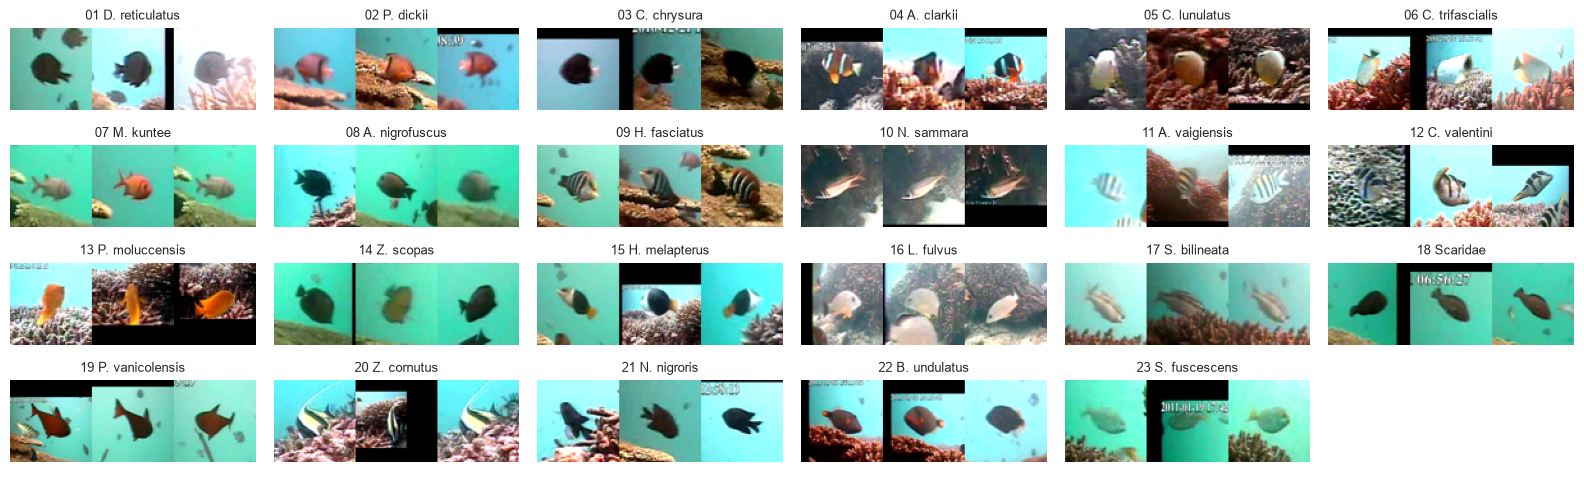

In [12]:
# 3.9 Three random images of every species.
# The window gives each image a random rank inside its species, and I keep ranks 1 to 3.

w = Window.partitionBy("class_id").orderBy(F.rand(SEED))

samples = (fish.filter("height > 0").withColumn("r", F.row_number().over(w)).filter("r <= 3")
               .select("class_id", "uri").orderBy("class_id").toPandas())

ids = sorted(samples.class_id.unique())


# Six species per row. Empty spaces in the grid are switched off.
fig, axes = plt.subplots(len(ids) // 6 + 1, 6, figsize=(16, 1.25 * (len(ids) // 6 + 1)))

for ax in axes.ravel(): ax.axis("off")

# The three images are resized to 64 x 64 and placed side by side.
for ax, cid in zip(axes.ravel(), ids):
    row = samples[samples.class_id == cid].uri.tolist()
    tiles = [np.asarray(Image.open(p).convert("RGB").resize((64, 64))) for p in row]

    ax.imshow(np.hstack(tiles)); ax.set_title(short_name(cid), fontsize=9)

savefig("07_sample_images")

### 3.10 EDA summary: how the findings shape the model

| EDA finding (from the outputs above) | Decision for training |
|---|---|
| Severe class imbalance: D. reticulatus is 44.3% of images; largest/smallest = 757 : 1 | Macro-F1 and balanced accuracy as the main metrics; class weights tested in Model 2 |
| 3.1 frames per fish on average (up to 92), almost identical | Stratified group split by trajectory to prevent leakage |
| 7 species have only 5–8 individual fish | Keep species with ≥ 15 trajectories so each split has unseen fish |
| Small images: median 95 × 88 px, 95% under 175 × 157 px; aspect ratio varies by species | 64 × 64 input, padded rather than stretched |
| Colour differs by species | Keep RGB (confirmed with the ANOVA test in Section 5) |
| Variable light, contrast and blur; some frames have burned-in camera timestamps | Keep these images (real-world conditions); test augmentation (contrast, zoom, rotation, flip) |
| 314 exact duplicates; no corrupt files; every image has a mask | Remove duplicates before splitting (Section 4) |
| Fish covers only about 13% of each crop | Use full crops (as at deployment); global average pooling tested in Model 2 |

## 4. Data cleaning (Spark)
Each rule below comes from the EDA. The row count is logged after every step so the effect of each rule is visible.

In [13]:
# Keeping the row count after every step so I can show what each cleaning rule removes.


steps = []
clean = fish
steps.append(("Fish images loaded", clean.count()))

# Step 1: remove files that couldn't be opened.
clean = clean.filter(F.col("height") > 0)


steps.append(("Remove unreadable / corrupt files", clean.count()))

# Step 2: remove images too small to classify.
clean = clean.filter((F.col("height") >= MIN_SIDE) & (F.col("width") >= MIN_SIDE))
steps.append((f"Remove images smaller than {MIN_SIDE}px", clean.count()))

# Step 3: an identical image with two different species labels can't be trusted, so every copy goes.

# left_anti keeps only the rows whose hash is NOT in the conflict list.
conflict_hashes = (clean.groupBy("hash").agg(F.countDistinct("class_id").alias("n")).filter("n > 1").select("hash"))
clean = clean.join(conflict_hashes, "hash", "left_anti")

steps.append(("Remove identical images with conflicting labels", clean.count()))

# Step 4: keep one copy of each exact duplicate. I rank the copies by file path and keep rank 1, so the same copy is kept every run.

clean = (clean.withColumn("rn", F.row_number().over(Window.partitionBy("hash").orderBy("uri"))).filter("rn = 1").drop("rn"))
steps.append(("Keep one copy of each exact duplicate", clean.count()))

# Step 5: keep species with at least 15 individual fish, so train, validation and test can all get different fish.

kept_classes = (clean.groupBy("class_id").agg(F.countDistinct("traj_key").alias("n_traj")).filter(F.col("n_traj") >= MIN_TRAJ).select("class_id"))
dropped = sorted(set(cs.class_id) - set(r.class_id for r in kept_classes.collect()))
clean = clean.join(kept_classes, "class_id").cache()
steps.append((f"Keep species with >= {MIN_TRAJ} trajectories", clean.count()))

# The difference between steps is the number of rows each rule removed.

cleaning_log = pd.DataFrame(steps, columns=["step", "rows_remaining"])
cleaning_log["rows_removed"] = (-cleaning_log.rows_remaining.diff()).fillna(0).astype(int)

display(cleaning_log)
print("Species removed for having too few trajectories:", [short_name(c) for c in dropped])

# The brief needs at least 10 000 records, so I check that the cleaned data still meets it.
n_final = cleaning_log.rows_remaining.iloc[-1]
print(f"Final dataset: {n_final:,} images -", "meets" if n_final >= 10000 else "BELOW", "the 10 000-record minimum in the brief")

,step,rows_remaining,rows_removed
0,Fish images loaded,27370,0
1,Remove unreadable / corrupt files,27370,0
2,Remove images smaller than 16px,27370,0
3,Remove identical images with conflicting labels,27370,0
4,Keep one copy of each exact duplicate,27056,314
5,Keep species with >= 15 trajectories,26835,221


Species removed for having too few trajectories: ['17 S. bilineata', '18 Scaridae', '19 P. vanicolensis', '20 Z. cornutus', '21 N. nigroris', '22 B. undulatus', '23 S. fuscescens']
Final dataset: 26,835 images - meets the 10 000-record minimum in the brief


Why these species are dropped rather than oversampled:<br> The dropped species each have only a handful of individual fish. With that few trajectories, it isn't possible to put different fish into train, validation and test, so any score for them would measure memorisation, not recognition. They are listed in the report as a data-collection recommendation.

## 5. Feature selection

A CNN learns its own features from pixels, so p-value elimination cannot be applied to individual pixels (there are 12 288 of them, and they are highly correlated). Feature selection here means choosing which inputs the CNN receives, backed by statistics:

1. ANOVA F-test with p-value selection in Spark (UnivariateFeatureSelector, ANOVA mode, p < 0.05). For each image descriptor, does its mean differ significantly between species? A small p-value (< 0.05) means the descriptor carries species information, so the input that carries it should be kept.
2. Correlation check: This finds descriptors that measure the same thing.

,descriptor,F_value,p_value,selected by Spark (p<0.05)
0,mean_g,919.3,0.00e+00,True
1,brightness,800.5,0.00e+00,True
2,mean_b,794.6,0.00e+00,True
3,sharpness,791.8,0.00e+00,True
4,contrast,612.8,0.00e+00,True
5,fish_area,505.0,0.00e+00,True
6,mean_r,443.9,0.00e+00,True
7,aspect,210.4,0.00e+00,True
8,height,135.5,0.00e+00,True
9,width,128.8,0.00e+00,True


Spark UnivariateFeatureSelector kept: ['mean_r', 'mean_g', 'mean_b', 'brightness', 'contrast', 'sharpness', 'width', 'height', 'aspect', 'fish_area']
Not significant: none


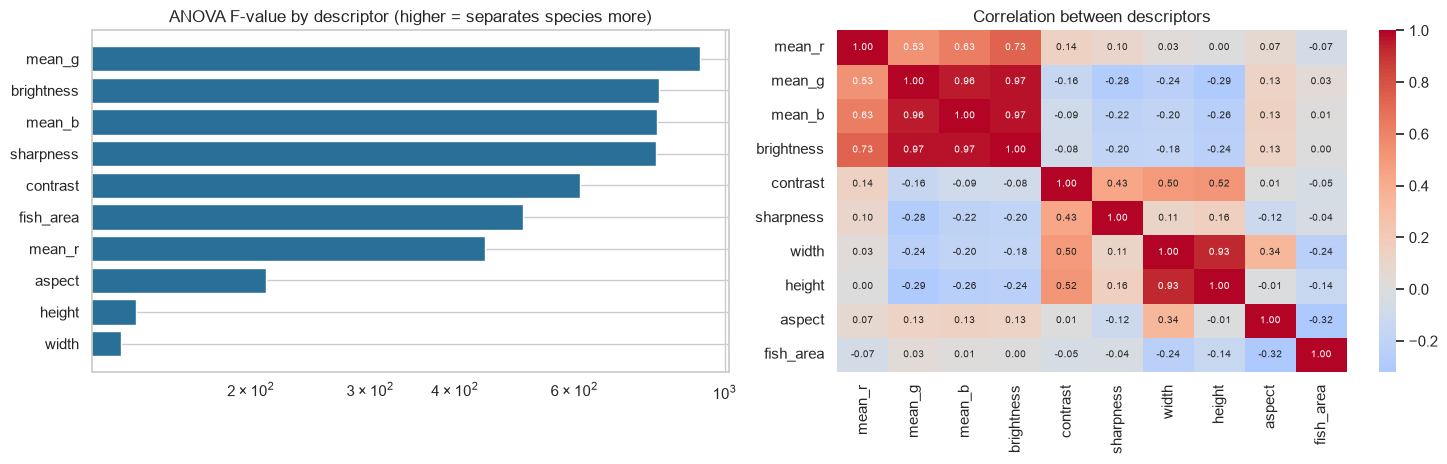

In [14]:
from pyspark.ml.feature import VectorAssembler, UnivariateFeatureSelector
from scipy.stats import f as f_dist

# The ten image descriptors I test. Fish area comes from the masks, so I join them first.

fs_df = clean.join(mask_area, ["class_id", "key"], "left")

feat_cols = ["mean_r", "mean_g", "mean_b", "brightness", "contrast", "sharpness", "width", "height", "aspect", "fish_area"]
fs_in = fs_df.na.drop(subset=feat_cols)


# a) One-way ANOVA worked out from Spark aggregations.

# Spark gives me the count, mean and variance per species, and I combine them below.
grp = fs_in.groupBy("class_id").agg(F.count("*").alias("n"),
                                    *[F.avg(c).alias(f"{c}__mean") for c in feat_cols],
                                    *[F.var_samp(c).alias(f"{c}__var") for c in feat_cols]).toPandas().fillna(0)
N, k = grp.n.sum(), len(grp)
rows = []

# F = variance between species / variance within species. A big F means the descriptor separates species well.

# ssb is the spread of the species means around the overall mean; ssw is the spread inside each species.


for c in feat_cols:
    grand = (grp.n * grp[f"{c}__mean"]).sum() / N
    ssb = (grp.n * (grp[f"{c}__mean"] - grand) ** 2).sum()
    ssw = ((grp.n - 1) * grp[f"{c}__var"]).sum()
    F_val = (ssb / (k - 1)) / (ssw / (N - k)) if ssw > 0 else np.inf
    # The p-value comes from the F distribution with k-1 and N-k degrees of freedom.
    rows.append((c, F_val, f_dist.sf(F_val, k - 1, N - k)))
anova = pd.DataFrame(rows, columns=["descriptor", "F_value", "p_value"]).sort_values("F_value", ascending=False).reset_index(drop=True)


# b) Spark ML p-value selection: UnivariateFeatureSelector runs the same ANOVA testand keeps every descriptor with p < 0.05 (the "fpr" mode).

vec = VectorAssembler(inputCols=feat_cols, outputCol="features").transform(fs_in).withColumn("label", F.col("class_id").cast("double"))
selector = (UnivariateFeatureSelector(featuresCol="features", labelCol="label", outputCol="selected", selectionMode="fpr")
            .setFeatureType("continuous").setLabelType("categorical").setSelectionThreshold(0.05))
selected = [feat_cols[i] for i in selector.fit(vec).selectedFeatures]
anova["selected by Spark (p<0.05)"] = anova.descriptor.isin(selected)
display(anova.style.format({"F_value": "{:,.1f}", "p_value": "{:.2e}"}))

print("Spark UnivariateFeatureSelector kept:", selected)
print("Not significant:", [c for c in feat_cols if c not in selected] or "none")

# c) F-values (log scale) and a correlation heatmap to spot descriptors that measure the same thing.
# The correlation uses a sample of about 20 000 rows, which is plenty for a heatmap.


fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].barh(anova.descriptor[::-1], anova.F_value[::-1], color="#2a6f97")
axes[0].set_xscale("log"); axes[0].set_title("ANOVA F-value by descriptor (higher = separates species more)")
corr = fs_df.select(feat_cols).na.drop().sample(fraction=min(1.0, 20000 / max(1, clean.count())), seed=SEED).toPandas().corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("Correlation between descriptors")
savefig("08_feature_selection")

Decisions from the feature analysis:<br> All ten descriptors were selected by Spark (p < 0.001; the p-values print as 0 because they are smaller than the computer can store).

| Evidence | Input decision |
|---|---|
| Mean green (F = 919), mean blue (795) and mean red (444) are significant; green is the strongest separator | Keep all 3 colour channels; grayscale would throw away the most useful information |
| Aspect ratio (F = 210), height (135) and width (129) differ by species but are the weakest separators | The shape is useful, so it is preserved with padding. Absolute pixel size depends on camera distance, so every image is rescaled to the same size |
| Sharpness (F = 792) and contrast (613) vary strongly | Kept as natural variation and handled by augmentation, not removed |
| Brightness is almost perfectly correlated with mean green and blue (r = 0.97); width and height correlate at 0.93 | Redundant; the CNN sees the raw channels, so no separate brightness input is needed |
| Fish area (from masks, F = 505) differs between species | Background matters, but masks are not available at inference, so the full crop is used |

Final input specification: RGB, 64 × 64 px, aspect ratio preserved by padding, pixel values scaled to [0, 1] inside the model, 16 species (26 835 images).

## 6. Train / validation / test split and input pipeline
StratifiedGroupKFold keeps every trajectory in exactly one split (group) while keeping species proportions similar (stratified): 20% test, then 25% of the rest for validation, giving roughly 60 / 20 / 20 (train / validation / test).

In [15]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

# Moving the cleaned rows from Spark to pandas for the split and for TensorFlow.


# The file location is renamed to "path" here, which is the name the tf.data pipeline and error analysis use.
df = clean.select(F.col("uri").alias("path"), "class_id", "traj_key", *feat_cols[:-1]).toPandas()


# Keras needs labels 0 to 15, so I map the species numbers to consecutive labels.

class_ids = sorted(df.class_id.unique())

id_to_label = {cid: i for i, cid in enumerate(class_ids)}
class_names = [short_name(c) for c in class_ids]
df["label"] = df.class_id.map(id_to_label)
N_CLASSES = len(class_ids)

# Step 1: 20% of the fish go to the test set (one fold out of five).
# I group by trajectory so every frame of one fish lands in the same split, otherwise the test setwould contain fish the model has already seen. Stratified keeps the species proportions similar.
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trv_idx, test_idx = next(outer.split(df, df.label, groups=df.traj_key))
trv, test_df = df.iloc[trv_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)

# Step 2: 25% of the remaining 80% becomes validation, which gives 60/20/20.


inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
tr_idx, val_idx = next(inner.split(trv, trv.label, groups=trv.traj_key))
train_df, val_df = trv.iloc[tr_idx].reset_index(drop=True), trv.iloc[val_idx].reset_index(drop=True)

# Images per species in each split. Every species needs images in all three.

split_table = pd.DataFrame({"train": train_df.class_id.value_counts(), "val": val_df.class_id.value_counts(),"test": test_df.class_id.value_counts()}).fillna(0).astype(int).sort_index()
split_table.index = [short_name(c) for c in split_table.index]
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)
missing = [c for c in split_table.index[:-1] if (split_table.loc[c] == 0).any()]

print("Classes missing from a split:", missing or "none")

# Leakage check: how many test images would share a fish with training if I had split randomly instead?
r_tr, r_te = train_test_split(df, test_size=0.2, stratify=df.label, random_state=SEED)
leak_random = r_te.traj_key.isin(set(r_tr.traj_key)).mean()
leak_grouped = test_df.traj_key.isin(set(train_df.traj_key) | set(val_df.traj_key)).mean()
print(f"Random split : {leak_random:.1%} of test images come from a fish that is also in training (leakage)")
print(f"Grouped split: {leak_grouped:.1%} of test images come from a fish that is also in training")

,train,val,test
01 D. reticulatus,7150,2384,2384
02 P. dickii,1599,534,533
03 C. chrysura,2125,709,709
04 A. clarkii,2426,809,808
05 C. lunulatus,1520,507,507
06 C. trifascialis,111,38,38
07 M. kuntee,265,88,89
08 A. nigrofuscus,126,42,42
09 H. fasciatus,143,48,48
10 N. sammara,179,60,60


Classes missing from a split: none
Random split : 82.4% of test images come from a fish that is also in training (leakage)
Grouped split: 0.0% of test images come from a fish that is also in training


TensorFlow 2.21.0 | Keras 3.15.1
Batch shape: (64, 64, 64, 3) | pixel range: 0.0 - 255.0


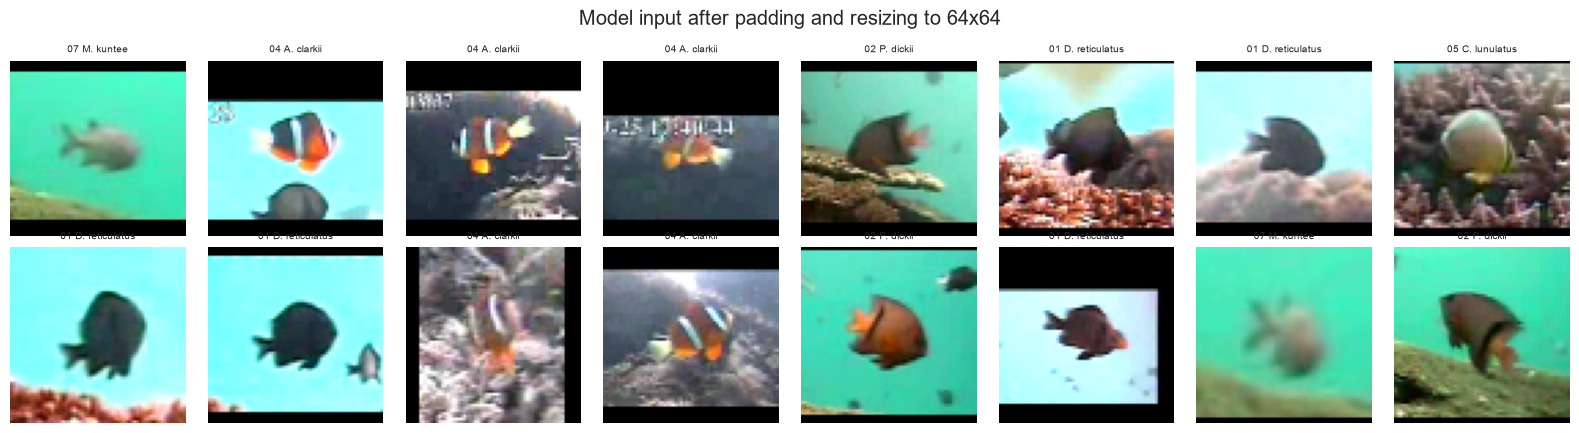

In [16]:
import tensorflow as tf
import keras
from keras import layers

# Same seed for TensorFlow and Keras so the training is repeatable.
tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)


# Reads one image and pads it to 64 x 64. Padding keeps the fish's shape instead of stretching it.
def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize_with_pad(img, IMG_SIZE, IMG_SIZE)
    # Stored as whole numbers (uint8) so the cached images take up less memory.
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), label

# Builds a tf.data pipeline. cache() decodes each image once and reuses it every epoch.


# Only the training set is shuffled. The values become decimals again just before batches go to the model.
def make_ds(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.label.values.astype("int32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)


train_ds, val_ds, test_ds = make_ds(train_df, shuffle=True), make_ds(val_df), make_ds(test_df)

# The test set is not shuffled, so these labels line up with the model's predictions later.
y_test = test_df.label.values

# Checking one batch: its shape, its pixel range, and what the model will actually see.
xb, yb = next(iter(train_ds))

print("Batch shape:", xb.shape, "| pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(xb[i].numpy().astype("uint8")); ax.set_title(class_names[int(yb[i])], fontsize=7); ax.axis("off")
plt.suptitle(f"Model input after padding and resizing to {IMG_SIZE}x{IMG_SIZE}")
savefig("09_model_input_batch")

## 7. Model 1: baseline CNN

| Hyperparameter | Value | Reason |
|---|---|---|
| Architecture | 3 × [Conv 3×3 → ReLU → MaxPool], filters 32 → 64 → 128 | Standard pattern: early layers detect edges, later layers detect fins and stripes; doubling the filters as the resolution halves keeps the computation balanced |
| Classifier head | Flatten → Dense(128, ReLU) → Dropout(0.5) → Softmax(N classes) | Softmax gives a probability per species; dropout limits overfitting [8] |
| Loss | Sparse categorical cross-entropy | Multi-class problem with integer labels |
| Optimiser | Adam, learning rate 0.001 | A reliable default that adapts the step size per weight [9] |
| Batch size / epochs | 64 / 10 | Fits in laptop memory; enough epochs to see whether the model is learning while keeping CPU training short |
| Imbalance handling | None (deliberately) | Measures how the plain model copes, so the retrain has a clear reference |

In [17]:
# Model 1: three convolution and pooling blocks, then a small dense classifier.

# Rescaling divides the pixels by 255 inside the model, so the saved model accepts raw images.

# The filters double (32, 64, 128) each time pooling halves the image size.
# Dropout(0.5) switches off half the dense units during training to reduce overfitting.
def build_baseline(n_classes):
    return keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax"),
    ], name="model1_baseline_cnn")

# Adam with learning rate 0.001. Sparse categorical cross-entropy because my labels are whole numbers (0-15).

# Top-3 accuracy checks whether the right species is among the three most likely guesses.
model1 = build_baseline(N_CLASSES)
model1.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3")])
model1.summary()

# No class weights or augmentation on purpose, so Model 2 has a clear reference point.

t0 = time.time()
hist1 = model1.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASE, verbose=2)
train_time1 = time.time() - t0

print(f"Model 1 trained in {train_time1 / 60:.1f} min")

Model: "model1_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,144,016 (4.36 MB)

 Trainable params: 1,144,016 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
252/252 - 30s - 119ms/step - accuracy: 0.7744 - loss: 0.7631 - top3: 0.9280 - val_accuracy: 0.9057 - val_loss: 0.3360 - val_top3: 0.9735
Epoch 2/10
252/252 - 22s - 87ms/step - accuracy: 0.9085 - loss: 0.3119 - top3: 0.9785 - val_accuracy: 0.9411 - val_loss: 0.2346 - val_top3: 0.9855
Epoch 3/10
252/252 - 23s - 92ms/step - accuracy: 0.9412 - loss: 0.2019 - top3: 0.9891 - val_accuracy: 0.9501 - val_loss: 0.1902 - val_top3: 0.9899
Epoch 4/10
252/252 - 20s - 79ms/step - accuracy: 0.9525 - loss: 0.1599 - top3: 0.9927 - val_accuracy: 0.9625 - val_loss: 0.1583 - val_top3: 0.9924
Epoch 5/10
252/252 - 18s - 72ms/step - accuracy: 0.9630 - loss: 0.1246 - top3: 0.9952 - val_accuracy: 0.9618 - val_loss: 0.1590 - val_top3: 0.9922
Epoch 6/10
252/252 - 21s - 82ms/step - accuracy: 0.9665 - loss: 0.1077 - top3: 0.9967 - val_accuracy: 0.9655 - val_loss: 0.1555 - val_top3: 0.9924
Epoch 7/10
252/252 - 21s - 85ms/step - accuracy: 0.9707 - loss: 0.0952 - top3: 0.9971 - val_accuracy: 0.9680 - val_lo

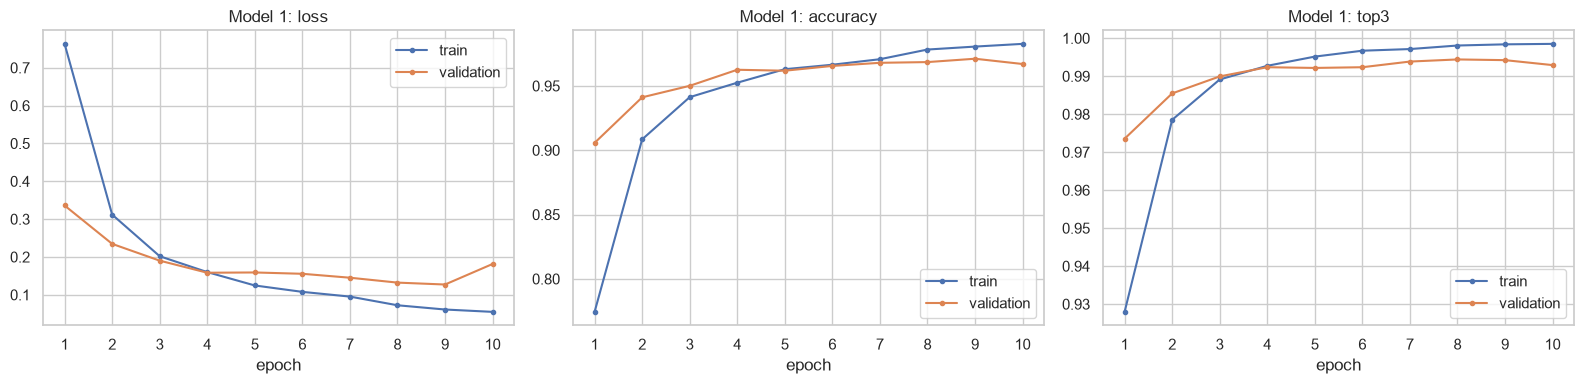

Best validation loss at epoch 9; final train-val accuracy gap = 0.016 (no strong overfitting)


In [18]:
# Plots loss, accuracy and top-3 accuracy per epoch for training and validation.


# I reuse this function for Model 2.
def plot_history(hist, name, fname):

    h = pd.DataFrame(hist.history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, m in zip(axes, ["loss", "accuracy", "top3"]):
        ep = np.arange(1, len(h) + 1)
        ax.plot(ep, h[m], marker="o", ms=3, label="train"); ax.plot(ep, h[f"val_{m}"], marker="o", ms=3, label="validation")
        ax.set_title(f"{name}: {m}"); ax.set_xlabel("epoch"); ax.legend()
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    savefig(fname)

    # A train accuracy more than 5 points above validation would point to overfitting.
    best = int(h.val_loss.idxmin())
    
    gap = h.accuracy.iloc[-1] - h.val_accuracy.iloc[-1]
    print(f"Best validation loss at epoch {best + 1}; final train-val accuracy gap = {gap:.3f} "
          f"({'possible overfitting' if gap > 0.05 else 'no strong overfitting'})")


plot_history(hist1, "Model 1", "10_model1_curves")

## 8. Evaluation of Model 1

Metrics and why they were chosen

| Metric | What it tells the client | Why it is needed here |
|---|---|---|
| Macro-F1 (main metric) | Average F1 over species, with every species counted equally | Not dominated by the majority species, so it shows whether rare species are recognised |
| Balanced accuracy | Average recall per species | How often each species is found, regardless of its size |
| Accuracy and weighted F1 | Overall hit rate | Familiar to the client, but must be read alongside macro-F1 |
| Top-3 accuracy | Is the true species among the 3 most likely guesses? | Useful when a human confirms the final match (e.g. a security guard) |
| Cohen's kappa | Agreement beyond chance | Corrects for the high accuracy that guessing the majority class gives |
| Per-class precision, recall, F1 and confusion matrix | Which species get confused with which | Points to where more data or a better model is needed |

All metrics are calculated on the test set only, which contains trajectories the model never saw.

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,cohen_kappa,top3_accuracy
model,,,,,,,,
Model 1 (baseline),0.9674,0.7099,0.8732,0.7099,0.7532,0.9623,0.9556,0.9963


,precision,recall,f1-score,support
01 D. reticulatus,0.952,0.996,0.973,2384.0
02 P. dickii,0.967,0.977,0.972,533.0
03 C. chrysura,0.987,0.963,0.975,709.0
04 A. clarkii,0.996,0.994,0.995,808.0
05 C. lunulatus,0.988,0.998,0.993,507.0
06 C. trifascialis,1.000,0.395,0.566,38.0
07 M. kuntee,0.977,0.955,0.966,89.0
08 A. nigrofuscus,1.000,0.167,0.286,42.0
09 H. fasciatus,0.824,0.875,0.848,48.0
10 N. sammara,0.983,0.983,0.983,60.0


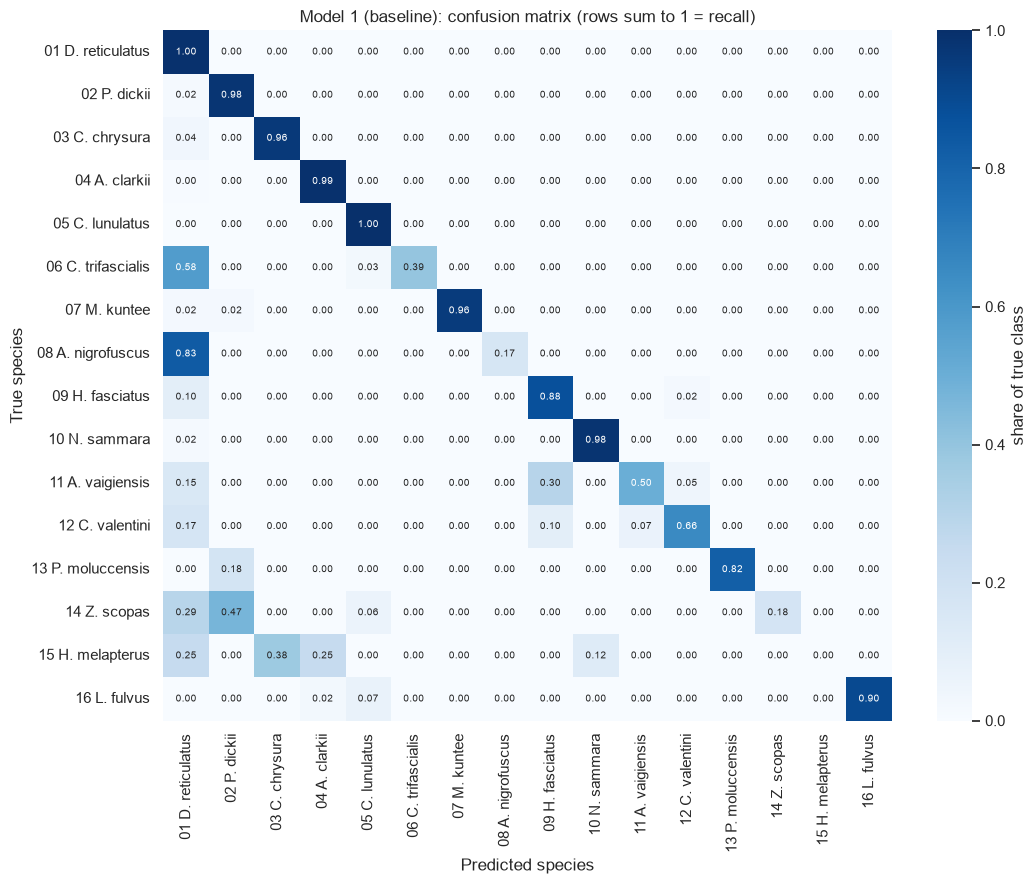

Accuracy - macro-F1 gap: 0.214 (a large gap means the common species hide weak performance on rare ones)
Weakest species by F1: 15 H. melapterus (F1=0.00, n=8), 14 Z. scopas (F1=0.27, n=17), 08 A. nigrofuscus (F1=0.29, n=42), 06 C. trifascialis (F1=0.57, n=38), 11 A. vaigiensis (F1=0.62, n=20)
Most common confusion: 08 A. nigrofuscus predicted as 01 D. reticulatus (83% of that species)


In [19]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, top_k_accuracy_score, cohen_kappa_score, classification_report, confusion_matrix)

# All my metrics in one place. Macro averages give every species the same weight, which matters with this imbalance.
# zero_division=0 stops a warning when a species is never predicted.

def score(name, y_true, y_pred, probs=None):
    m = {"model": name,
         "accuracy": accuracy_score(y_true, y_pred),
         "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
         "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
         "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
         "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
         "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
         "cohen_kappa": cohen_kappa_score(y_true, y_pred)}
    # Top-3 needs probabilities, so baselines without them get NaN.
    m["top3_accuracy"] = (top_k_accuracy_score(y_true, probs, k=3, labels=np.arange(N_CLASSES))
                          if probs is not None else np.nan)
    
    return m


# Evaluates a model on the test set only: metrics, per-species report, confusion matrix and a short diagnosis.
def evaluate(model, name, fig_name):
    # The predicted species is the one with the highest probability.
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)

    m = score(name, y_test, y_pred, probs)
    rep = pd.DataFrame(classification_report(y_test, y_pred, labels=np.arange(N_CLASSES), target_names=class_names, output_dict=True, zero_division=0)).T

    per_class = rep.loc[class_names, ["precision", "recall", "f1-score", "support"]]

    display(pd.DataFrame([m]).set_index("model").round(4))
    display(per_class.round(3))

    # Each row is divided by its total, so a row shows where that species' images went (the diagonal is recall).

    cm = confusion_matrix(y_test, y_pred, labels=np.arange(N_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    plt.figure(figsize=(11, 9))
    sns.heatmap(cmn, cmap="Blues", vmin=0, vmax=1, xticklabels=class_names, yticklabels=class_names,
                annot=N_CLASSES <= 16, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "share of true class"})
    plt.xlabel("Predicted species"); plt.ylabel("True species")

    plt.title(f"{name}: confusion matrix (rows sum to 1 = recall)")

    savefig(fig_name)

    # Printing the weakest species and the biggest confusion so I can quote them in my interpretation.


    worst = per_class.sort_values("f1-score").head(5)
    print(f"Accuracy - macro-F1 gap: {m['accuracy'] - m['macro_f1']:.3f} "
          
          "(a large gap means the common species hide weak performance on rare ones)")
    print("Weakest species by F1:", ", ".join(f"{i} (F1={r['f1-score']:.2f}, n={int(r.support)})" for i, r in worst.iterrows()))

    # The largest value off the diagonal is the most common mistake.
    off = cmn.copy(); np.fill_diagonal(off, 0)
    
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"Most common confusion: {class_names[i]} predicted as {class_names[j]} ({off[i, j]:.0%} of that species)")
    return m, probs, y_pred, per_class

m1, probs1, pred1, pc1 = evaluate(model1, "Model 1 (baseline)", "11_model1_confusion")

Interpretation of Model 1:<br>
- Strong overall performance: Model 1 identified 96.7% of unseen fish correctly (Cohen's kappa 0.956), and the right species was in its top three guesses 99.6% of the time. The five common species all score F1 ≥ 0.97.
- Rare species hide behind the accuracy: macro-F1 is 0.753, a gap of 0.21 below accuracy. H. melapterus (8 test images, 25 for training) was never recognised, and Z. scopas (F1 0.27) and A. nigrofuscus (F1 0.29) were mostly confused with look-alikes. 83% of A. nigrofuscus were predicted as D. reticulatus, another dark, deep-bodied fish.
- Cautious on rare species: their precision is high (often 1.00) but recall is low, so when unsure the model falls back on the common species. This is the classic effect of training on imbalanced data without reweighting.
- Learning curves: validation loss was lowest at epoch 9 and the final train–validation accuracy gap was only 1.6 points, so there is no strong overfitting. Validation loss rose slightly at epoch 10, so training longer would not have helped.

Shortcomings Model 2 is designed to fix:<br>
1. Imbalance bias: rare species have low recall (A. nigrofuscus 0.17, Z. scopas 0.18, C. trifascialis 0.39), so class weights are added.
2. Risk of memorising near-duplicate frames: Flatten → Dense holds most of the 1.14 million parameters, so augmentation and global average pooling are added.
3. Sensitivity to lighting and position: the EDA showed wide variation in brightness, contrast and framing, so augmentation is added.
4. Fixed training length: 10 epochs with no early stopping and a fixed learning rate, so early stopping and learning-rate reduction are added.

## 9. Model 2: retrained CNN (changes target the shortcomings above)

| Change | Shortcoming addressed |
|---|---|
| Class weights (square root of "balanced" weights) | Imbalance bias. Rare species count more in the loss; the square root avoids over-correcting the tiniest classes [10] |
| Data augmentation: horizontal flip, ±5% rotation, zoom, contrast | Overfitting and sensitivity to lighting and position [11] |
| Batch normalisation after every convolution | Trains faster and more stably [12] |
| Global average pooling instead of Flatten | Far fewer parameters, which reduces overfitting and makes the model less sensitive to where the fish sits in the crop |
| Dropout in every block (0.1 → 0.3) and 0.4 in the head | Regularisation |
| Early stopping (up to 15 epochs, patience 4, best weights restored) + learning-rate reduction (×0.5 after 2 epochs without improvement) | Trains for as long as validation loss improves and no longer |

In [20]:
from sklearn.utils.class_weight import compute_class_weight

# Change 1: class weights, so mistakes on rare species count more in the loss.


# I take the square root of the "balanced" weights so the tiniest species don't get extreme weights.

cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=train_df.label)
class_weight = {i: float(np.sqrt(w)) for i, w in enumerate(cw)}

display(pd.DataFrame({"species": class_names, "train images": np.bincount(train_df.label, minlength=N_CLASSES), "class weight": [round(class_weight[i], 2) for i in range(N_CLASSES)]}))

# Change 2: augmentation. Random flips, small rotations, zoom and contrast changes every batch, so the model can't simply memorise the near-identical frames.
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.15),
], name="augmentation")

# Change 3: one block = convolution, batch normalisation, ReLU, pooling and dropout.


# use_bias=False because batch normalisation already adds its own shift.

def conv_block(x, filters, drop):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(drop)(x)



# Change 4: global average pooling instead of Flatten, which cuts the parameters by about 90%.

# Dropout grows from 0.1 to 0.3 through the blocks. The augmentation is only active during training.
def build_improved(n_classes):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    x = conv_block(x, 32, 0.1)
    x = conv_block(x, 64, 0.2)
    x = conv_block(x, 128, 0.3)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="model2_improved_cnn")

# Same optimiser, loss and metrics as Model 1, so only my four changes differ.
model2 = build_improved(N_CLASSES)
model2.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
               metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3")])
model2.summary()
print(f"Parameters - Model 1: {model1.count_params():,} | Model 2: {model2.count_params():,}")

,species,train images,class weight
0,01 D. reticulatus,7150,0.38
1,02 P. dickii,1599,0.79
2,03 C. chrysura,2125,0.69
3,04 A. clarkii,2426,0.64
4,05 C. lunulatus,1520,0.81
5,06 C. trifascialis,111,3.01
6,07 M. kuntee,265,1.95
7,08 A. nigrofuscus,126,2.83
8,09 H. fasciatus,143,2.65
9,10 N. sammara,179,2.37


Model: "model2_improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,496 (439.44 KB)

 Trainable params: 112,048 (437.69 KB)

 Non-trainable params: 448 (1.75 KB)

Parameters - Model 1: 1,144,016 | Model 2: 112,496


Epoch 1/15
252/252 - 71s - 284ms/step - accuracy: 0.6577 - loss: 1.1792 - top3: 0.8781 - val_accuracy: 0.1530 - val_loss: 2.6008 - val_top3: 0.5415 - learning_rate: 0.0010
Epoch 2/15
252/252 - 59s - 234ms/step - accuracy: 0.7315 - loss: 0.8892 - top3: 0.9281 - val_accuracy: 0.6594 - val_loss: 1.1251 - val_top3: 0.8828 - learning_rate: 0.0010
Epoch 3/15
252/252 - 68s - 268ms/step - accuracy: 0.7672 - loss: 0.7460 - top3: 0.9388 - val_accuracy: 0.7047 - val_loss: 0.9278 - val_top3: 0.9208 - learning_rate: 0.0010
Epoch 4/15
252/252 - 70s - 276ms/step - accuracy: 0.7800 - loss: 0.6634 - top3: 0.9479 - val_accuracy: 0.6754 - val_loss: 0.9586 - val_top3: 0.9335 - learning_rate: 0.0010
Epoch 5/15
252/252 - 63s - 249ms/step - accuracy: 0.8013 - loss: 0.5925 - top3: 0.9554 - val_accuracy: 0.7537 - val_loss: 0.7262 - val_top3: 0.9339 - learning_rate: 0.0010
Epoch 6/15
252/252 - 78s - 310ms/step - accuracy: 0.8171 - loss: 0.5402 - top3: 0.9643 - val_accuracy: 0.8051 - val_loss: 0.5971 - val_top3:

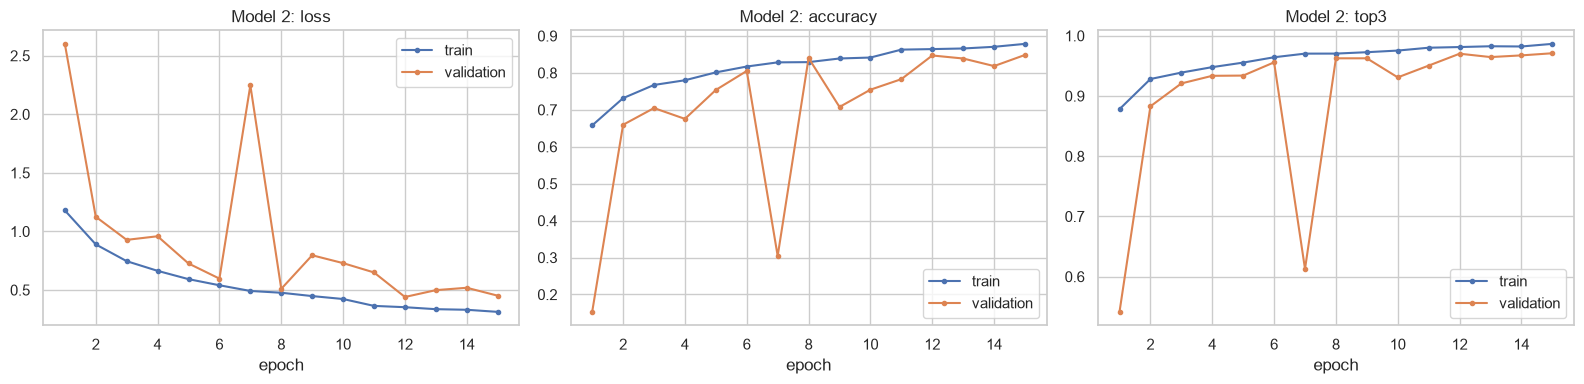

Best validation loss at epoch 12; final train-val accuracy gap = 0.030 (no strong overfitting)


In [21]:
# Early stopping ends training after 4 epochs without a better validation loss and keeps the best weights.

# The learning rate halves after 2 epochs without improvement. The best model is also saved to a file.


callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    keras.callbacks.ModelCheckpoint(os.path.join(OUT_DIR, "model2_best.keras"), monitor="val_loss", save_best_only=True),
]

# Training with the class weights from the previous cell.
t0 = time.time()

hist2 = model2.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_IMPROVED,
                   class_weight=class_weight, callbacks=callbacks, verbose=2)
train_time2 = time.time() - t0
print(f"Model 2 trained for {len(hist2.history['loss'])} epochs in {train_time2 / 60:.1f} min")
plot_history(hist2, "Model 2", "12_model2_curves")

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,cohen_kappa,top3_accuracy
model,,,,,,,,
Model 2 (retrained),0.8666,0.7327,0.6475,0.7327,0.6712,0.876,0.8262,0.9763


,precision,recall,f1-score,support
01 D. reticulatus,0.963,0.820,0.886,2384.0
02 P. dickii,0.880,0.921,0.900,533.0
03 C. chrysura,0.682,0.901,0.776,709.0
04 A. clarkii,0.992,0.934,0.962,808.0
05 C. lunulatus,0.968,0.957,0.962,507.0
06 C. trifascialis,0.750,0.632,0.686,38.0
07 M. kuntee,0.752,0.955,0.842,89.0
08 A. nigrofuscus,0.317,0.619,0.419,42.0
09 H. fasciatus,0.681,0.667,0.674,48.0
10 N. sammara,0.855,0.983,0.915,60.0


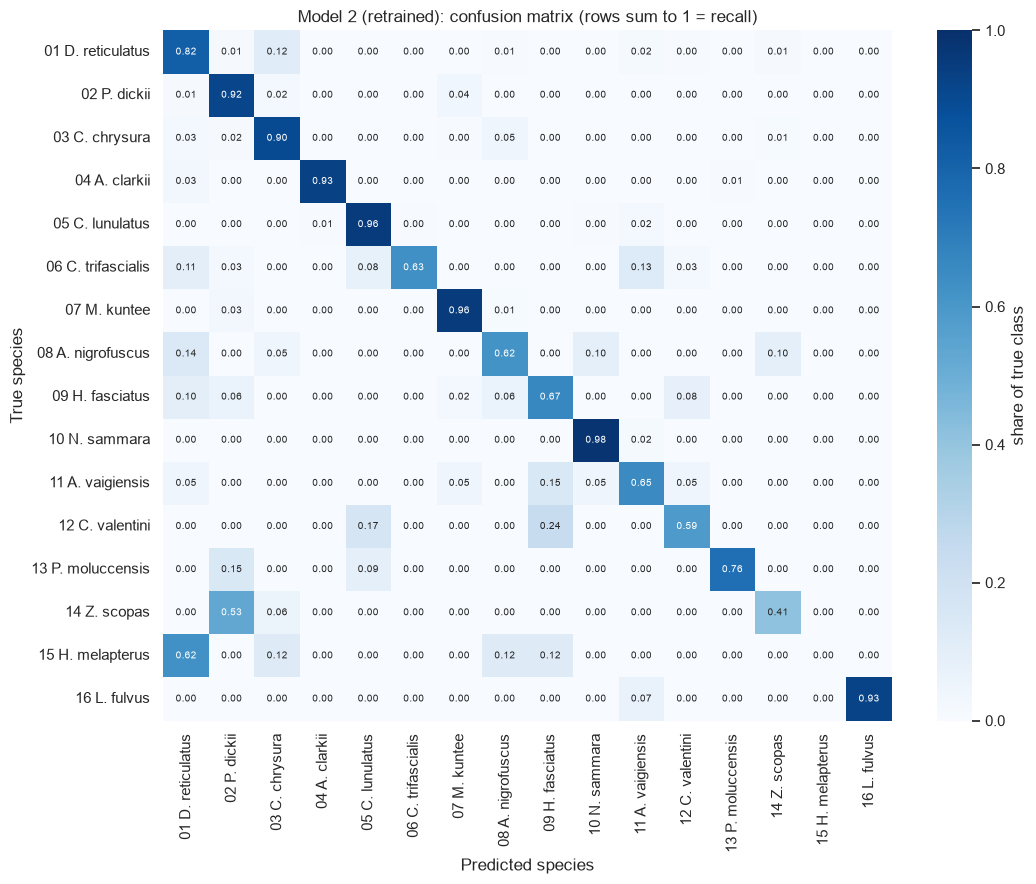

Accuracy - macro-F1 gap: 0.195 (a large gap means the common species hide weak performance on rare ones)
Weakest species by F1: 15 H. melapterus (F1=0.00, n=8), 14 Z. scopas (F1=0.20, n=17), 11 A. vaigiensis (F1=0.28, n=20), 08 A. nigrofuscus (F1=0.42, n=42), 12 C. valentini (F1=0.54, n=29)
Most common confusion: 15 H. melapterus predicted as 01 D. reticulatus (62% of that species)


In [22]:
m2, probs2, pred2, pc2 = evaluate(model2, "Model 2 (retrained)", "13_model2_confusion")

## 10. Model comparison and error analysis

Both CNNs are compared with two simple baselines to show that the CNN adds real value:
- Majority class: always predicts the most common species.
- Logistic regression on the descriptors from Sectionn 5 (colour, size, brightness, sharpness), the best a non-CNN model can do with hand-made features.

McNemar's test checks whether the difference between Model 1 and Model 2 on the *same* test images is statistically significant.

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,cohen_kappa,top3_accuracy
model,,,,,,,,
Majority-class baseline,0.444,0.062,0.028,0.062,0.038,0.273,0.000,nan
Logistic regression on descriptors,0.385,0.446,0.260,0.446,0.254,0.453,0.287,0.690
Model 1 (baseline),0.967,0.710,0.873,0.710,0.753,0.962,0.956,0.996
Model 2 (retrained),0.867,0.733,0.648,0.733,0.671,0.876,0.826,0.976


McNemar: Model 1 right / Model 2 wrong = 625; Model 1 wrong / Model 2 right = 84; p = 4.392e-103
-> The difference is statistically significant (p < 0.05).


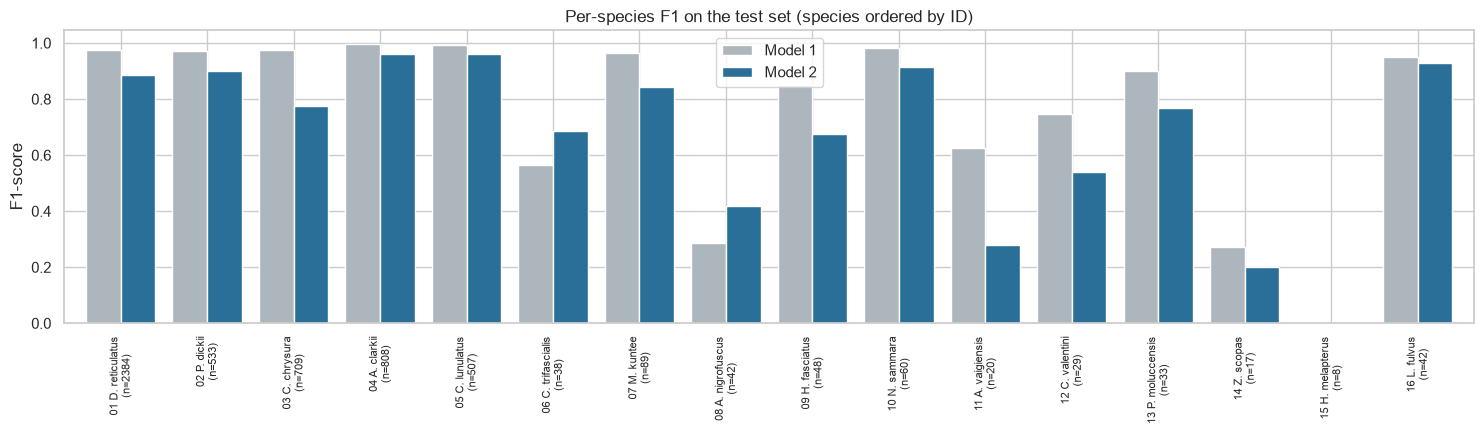

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from scipy.stats import binomtest


# Two simple baselines, to show the CNNs add real value.

# Fish area is left out because it comes from the masks, which won't exist for new images.
desc_cols = feat_cols[:-1]

# Baseline 1: always predict the most common training species.


majority = np.full_like(y_test, np.bincount(train_df.label).argmax())

# Baseline 2: logistic regression on my nine descriptors (scaled first, with balanced class weights).
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
lr.fit(train_df[desc_cols], train_df.label)

lr_probs = lr.predict_proba(test_df[desc_cols])

# Putting the probabilities in a 16-column table so top-3 accuracy works the same way as for the CNNs.

lr_full = np.zeros((len(test_df), N_CLASSES)); lr_full[:, lr.classes_] = lr_probs


# All four models side by side. The best value in each column is highlighted.


comparison = pd.DataFrame([
    score("Majority-class baseline", y_test, majority),
    score("Logistic regression on descriptors", y_test, lr_full.argmax(1), lr_full),
    m1, m2]).set_index("model")
display(comparison.style.format("{:.3f}").highlight_max(axis=0, color="#cdeac0"))


# McNemar's test: is the difference between Model 1 and Model 2 real or just chance?
# It only looks at the test images where exactly one of the two models is right.

c1, c2 = pred1 == y_test, pred2 == y_test


b, c = int(np.sum(c1 & ~c2)), int(np.sum(~c1 & c2))

# If both models were equally good, those disagreements would split 50/50. The exact binomial test checks that.

p_mcnemar = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0


print(f"McNemar: Model 1 right / Model 2 wrong = {b}; Model 1 wrong / Model 2 right = {c}; p = {p_mcnemar:.4g}")
print("-> The difference is", "statistically significant (p < 0.05)." if p_mcnemar < 0.05 else "not statistically significant.")

# Per-species F1 for both models, with the number of test images under each name.
f1_cmp = pd.DataFrame({"Model 1": pc1["f1-score"], "Model 2": pc2["f1-score"], "test images": pc1["support"].astype(int)})
ax = f1_cmp[["Model 1", "Model 2"]].plot.bar(figsize=(15, 4.5), color=["#adb5bd", "#2a6f97"], width=0.8)
ax.set_ylabel("F1-score"); ax.set_title("Per-species F1 on the test set (species ordered by ID)")

ax.set_xticklabels([f"{n}\n(n={s})" for n, s in zip(f1_cmp.index, f1_cmp["test images"])], rotation=90, fontsize=8)

savefig("14_per_class_f1_comparison")

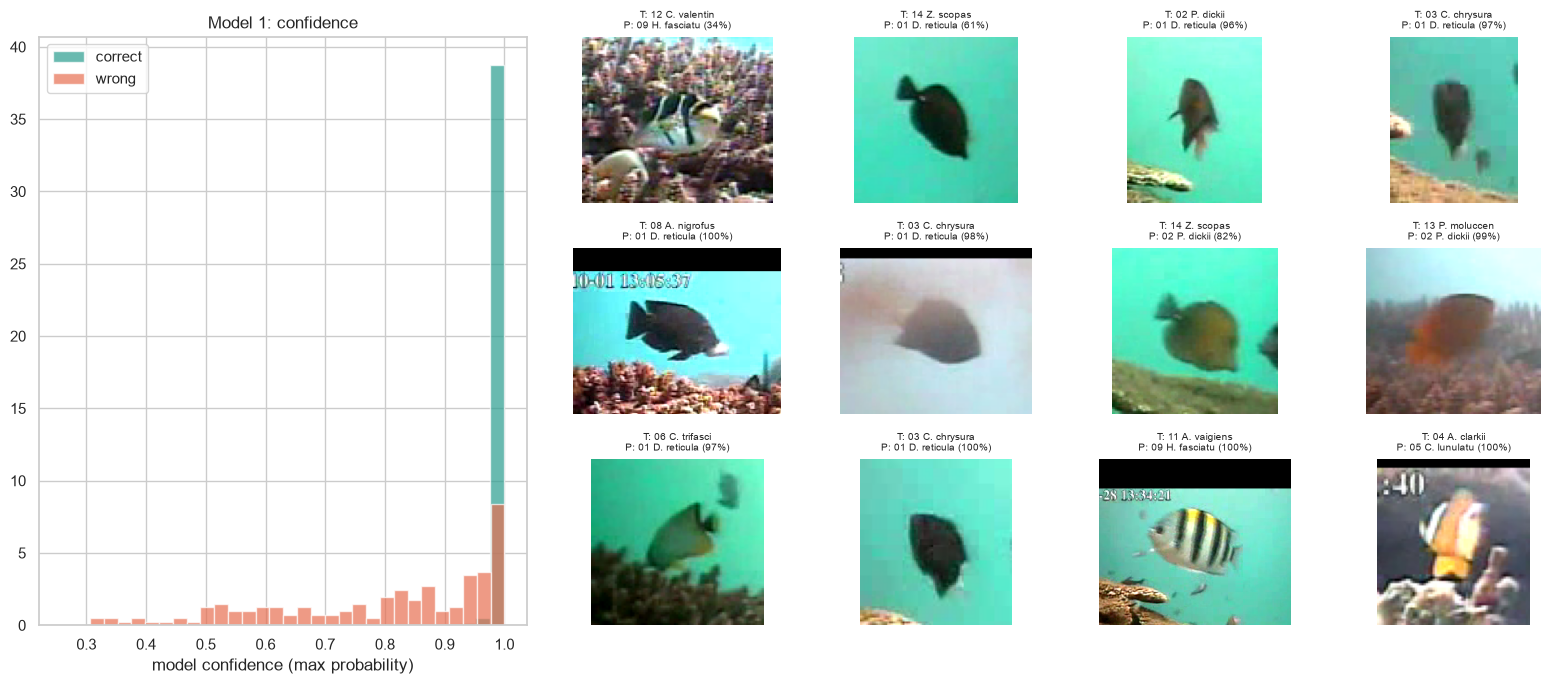

Confidence >= 50%: covers 99.6% of test images with accuracy 97.0%
Confidence >= 70%: covers 98.2% of test images with accuracy 97.7%
Confidence >= 90%: covers 96.1% of test images with accuracy 98.6%


In [24]:
# Error analysis on whichever model has the higher macro-F1 (my main metric).

best_name, best_model, best_probs, best_pred = (("Model 2", model2, probs2, pred2) if m2["macro_f1"] >= m1["macro_f1"]
                                               else ("Model 1", model1, probs1, pred1))

# Confidence is the highest probability the model gave for each image.

conf = best_probs.max(1)

wrong = np.where(best_pred != y_test)[0]

# a) Confidence of correct vs wrong predictions. density=True puts both on the same scale.

fig = plt.figure(figsize=(16, 7))
ax0 = fig.add_subplot(1, 3, 1)
ax0.hist(conf[best_pred == y_test], bins=30, alpha=.7, label="correct", color="#2a9d8f", density=True)
ax0.hist(conf[best_pred != y_test], bins=30, alpha=.7, label="wrong", color="#e76f51", density=True)
ax0.set_xlabel("model confidence (max probability)"); ax0.set_title(f"{best_name}: confidence"); ax0.legend()

# b) 12 random mistakes with the true species (T), the predicted species (P) and the confidence.

rng = np.random.default_rng(SEED)


show = rng.choice(wrong, size=min(12, len(wrong)), replace=False) if len(wrong) else []
for k, idx in enumerate(show):
    ax = fig.add_subplot(3, 6, (k // 4) * 6 + 3 + k % 4)
    ax.imshow(Image.open(test_df.path[idx]).convert("RGB")); ax.axis("off")
    ax.set_title(f"T: {class_names[y_test[idx]][:14]}\nP: {class_names[best_pred[idx]][:14]} ({conf[idx]:.0%})", fontsize=7)
savefig("15_error_analysis")

# c) If only confident predictions are accepted, how many images are covered and how accurate are they?
# The rest could go to a person for review.
for t in [0.5, 0.7, 0.9]:
    sel = conf >= t
    print(f"Confidence >= {t:.0%}: covers {sel.mean():.1%} of test images with accuracy {np.mean(best_pred[sel] == y_test[sel]):.1%}")

Interpreting the comparison:<br>
- Both CNNs beat the baselines by a wide margin: macro-F1 is 0.753 (Model 1) and 0.671 (Model 2), against 0.038 for always guessing the majority species and 0.254 for logistic regression on the hand-made descriptors. The CNNs learn shape and texture patterns that colour and size statistics alone cannot capture.
- The retrain traded precision for recall: class weights did raise rare-species recall. Balanced accuracy rose from 0.710 to 0.733, with recall up for A. nigrofuscus (0.17 → 0.62), C. trifascialis (0.39 → 0.63) and Z. scopas (0.18 → 0.41). But Model 2 now pushes many common-species images into rare classes (12% of D. reticulatus were predicted as C. chrysura), so macro precision fell from 0.873 to 0.648, macro-F1 fell to 0.671 and accuracy to 86.7%.
- The difference is statistically significant: Model 1 was right where Model 2 was wrong 625 times, against 84 the other way round (McNemar's test, p ≈ 4 × 10⁻¹⁰³). Model 1 is selected as the final model and saved as fish_cnn_final.keras.
- Why Model 2 underperformed: its validation curve was unstable (a sharp spike at epoch 7), and early stopping never triggered before the 15-epoch limit, so it may not have fully converged. Strong augmentation, batch normalisation and large class weights (up to 6.3) all make training noisier and slower. The next step would be to train it longer with milder class weights, or add only light augmentation to Model 1's architecture.
- Confidence is useful for deployment: for Model 1, accepting only predictions with at least 90% confidence still covers 96.1% of test images, at 98.6% accuracy. The remaining 3.9% can be sent to a person for review (for example, a security guard confirming a face match).
- Remaining errors (see the images above) are mostly dark, similar-shaped species confused with D. reticulatus, plus blurred crops and frames with burned-in timestamps, which matches the quality issues found in the EDA.

## 11. Save the model and results

In [25]:
# Saving the selected model so it can be loaded later without retraining.

best_model.save(os.path.join(OUT_DIR, "fish_cnn_final.keras"))

# results collects the numbers I quote in the report, so the report and the notebook always agree.

results = {
    "dataset": {"files_loaded": int(n_files), "fish_images": int(cs.images.sum()), "species_total": int(len(cs)),
                "species_kept": int(N_CLASSES), "species_dropped": [short_name(c) for c in dropped],
                "imbalance_ratio": float(cs.images.max() / cs.images.min())},
    "cleaning_log": cleaning_log.to_dict(orient="records"),
    "quality_checks": quality_checks.to_dict(orient="records"),
    "split_sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "leakage": {"random_split": float(leak_random), "grouped_split": float(leak_grouped)},
    "anova": anova.to_dict(orient="records"),
    "spark_selected_descriptors": selected,
    "metrics": comparison.reset_index().to_dict(orient="records"),
    "mcnemar_p": float(p_mcnemar),
    "epochs": {"model1": len(hist1.history["loss"]), "model2": len(hist2.history["loss"])},
    "train_minutes": {"model1": round(train_time1 / 60, 1), "model2": round(train_time2 / 60, 1)},
    "params": {"model1": int(model1.count_params()), "model2": int(model2.count_params())},
    "per_class_f1": f1_cmp.reset_index().rename(columns={"index": "species"}).to_dict(orient="records"),
}

# default=float turns NumPy numbers into normal numbers that JSON can store.
with open(os.path.join(OUT_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2, default=float)

print("Saved: outputs/fish_cnn_final.keras, outputs/results.json and", len(os.listdir(FIG_DIR)), "figures in outputs/figures")
print("\n========== SUMMARY FOR THE REPORT ==========")
print(json.dumps({k: results[k] for k in ["dataset", "split_sizes", "leakage", "epochs", "train_minutes", "mcnemar_p"]}, indent=1, default=float))
print(comparison.round(3).to_string())

Saved: outputs/fish_cnn_final.keras, outputs/results.json and 15 figures in outputs/figures

========== SUMMARY FOR THE REPORT ==========
{
 "dataset": {
  "files_loaded": 54740,
  "fish_images": 27370,
  "species_total": 23,
  "species_kept": 16,
  "species_dropped": [
   "17 S. bilineata",
   "18 Scaridae",
   "19 P. vanicolensis",
   "20 Z. cornutus",
   "21 N. nigroris",
   "22 B. undulatus",
   "23 S. fuscescens"
  ],
  "imbalance_ratio": 757.0
 },
 "split_sizes": {
  "train": 16101,
  "val": 5367,
  "test": 5367
 },
 "leakage": {
  "random_split": 0.8239239798770263,
  "grouped_split": 0.0
 },
 "epochs": {
  "model1": 10,
  "model2": 15
 },
 "train_minutes": {
  "model1": 3.6,
  "model2": 15.2
 },
 "mcnemar_p": 4.391611945393822e-103
}
                                    accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  cohen_kappa  top3_accuracy
model                                                                                                 

In [26]:
spark.stop()

## 12. Conclusions, limitations and recommendations

Conclusions:<br>
- Spark profiled all 54 740 image and mask files: size, quality, colour, duplicates and trajectories. Two findings shaped the whole modelling approach: extreme class imbalance (757 : 1) and near-duplicate video frames, where a random split would have leaked 82.4% of test images.
- Splitting by trajectory gives an honest estimate of how the model performs on new individuals, which is what the publisher needs for people it has never enrolled.
- Final model: Model 1, with 96.7% accuracy, 0.753 macro-F1 and 99.6% top-3 accuracy on unseen fish. The retrained Model 2 improved rare-species recall (balanced accuracy 0.733) but lost more in precision, and McNemar's test confirms Model 1 is significantly better.

Limitations:<br>
- Rare species are still represented by very few individual fish (H. melapterus: 16 in total), so their scores have wide uncertainty.
- Inputs are 64 × 64 px, so fine details in the larger crops are lost.
- Only one random grouped split was evaluated, and Model 2 was limited to 15 epochs on a laptop CPU.

Recommendations for the facial-recognition rollout:<br>
1. Collect several individuals per class (several people per role or site, several sessions per person). This dataset shows that number of individuals matters more than number of frames.
2. Use transfer learning (for example MobileNetV2 or a pretrained face-embedding network) once face data exists, because it needs far fewer images per person.
3. Keep group-based splitting (by person and by camera session) to avoid inflated scores.
4. Send predictions below 90% confidence to a person for review.
5. Comply with POPIA: face images are biometric special personal information, so they need consent, a clear purpose, secure storage and retention limits.

## References

[1] madhushreesannigrahi, “Fish recognition ground-truth data,” Kaggle. [Online]. Available: https://www.kaggle.com/datasets/madhushreesannigrahi/fish-recognition-ground-truth-data/data.

[2] R. B. Fisher, P. X. Huang, and B. J. Boom, “Fish recognition ground-truth data,” Fish4Knowledge project, University of Edinburgh, 2013. [Online]. Available: https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/.

[3] B. J. Boom, P. X. Huang, J. He, and R. B. Fisher, “Supporting ground-truth annotation of image datasets using clustering,” in *Proc. 21st Int. Conf. Pattern Recognit. (ICPR)*, Tsukuba, Japan, 2012.

[4] S. Kaufman, S. Rosset, C. Perlich, and O. Stitelman, “Leakage in data mining: Formulation, detection, and avoidance,” *ACM Trans. Knowl. Discov. Data*, vol. 6, no. 4, pp. 1–21, 2012.

[5] M.-C. Chuang, J.-N. Hwang, and K. Williams, “A feature learning and object recognition framework for underwater fish images,” *IEEE Trans. Image Process.*, vol. 25, no. 4, 2016, doi: 10.1109/TIP.2016.2535342.

[6] *Protection of Personal Information Act 4 of 2013*, Republic of South Africa, 2013.

[7] The Apache Software Foundation, “PySpark documentation,” 2026. [Online]. Available: https://spark.apache.org/docs/latest/api/python/.

[8] N. Srivastava, G. Hinton, A. Krizhevsky, I. Sutskever, and R. Salakhutdinov, “Dropout: A simple way to prevent neural networks from overfitting,” *J. Mach. Learn. Res.*, vol. 15, pp. 1929–1958, 2014.

[9] D. P. Kingma and J. Ba, “Adam: A method for stochastic optimization,” in *Proc. 3rd Int. Conf. Learn. Represent. (ICLR)*, San Diego, CA, USA, 2015.

[10] M. Buda, A. Maki, and M. A. Mazurowski, “A systematic study of the class imbalance problem in convolutional neural networks,” *Neural Netw.*, vol. 106, pp. 249–259, 2018.

[11] C. Shorten and T. M. Khoshgoftaar, “A survey on image data augmentation for deep learning,” *J. Big Data*, vol. 6, no. 60, 2019.

[12] S. Ioffe and C. Szegedy, “Batch normalization: Accelerating deep network training by reducing internal covariate shift,” in *Proc. 32nd Int. Conf. Mach. Learn. (ICML)*, 2015, pp. 448–456.